# NB-11 · Stage 11 — Deployment and inference (Step 11)

**Project:** HiDMamba, hierarchical distillation for 12-lead ECG (PTB-XL, 100 Hz)
**Runtime:** Kaggle GPU (T4) or CPU. About 5 to 8 minutes. Nothing is trained and nothing is tuned: this stage *uses* the artefacts of Stages 3, 8, 9 and 10.

Synopsis, Step 11: *capture a new ECG sample; pass it through the deployed Chief Resident (patchifier, Mamba block, classification head) to get per-label probabilities; apply the calibrated thresholds to get diagnostic labels; query the FAISS index with the sample's DEAN embedding to retrieve the nearest prototype ECGs; return the prediction with a prototype-based explanation; repeat for the next incoming sample.*

### What this notebook adds to the pipeline of Stage 10
`hidmamba_infer.py` (written in Stage 10) is the model pipeline. This stage wraps it into a **service** that can be handed new records, in `hidmamba_deploy.py`:

| Step of the synopsis | Where it happens |
|---|---|
| 1 Capture a new ECG | **input gate** `validate_ecg`: shape, length, NaN, flat leads and amplitude (unit errors) are checked; a bad record is rejected with a reason instead of producing a confident wrong answer |
| 2 Chief Resident probabilities | `HiDMambaPipeline`: patchifier → one bidirectional Mamba block → head, fp32, Platt-calibrated |
| 3 Calibrated thresholds | the 26 per-label thresholds frozen on fold 9 in Stage 10 |
| 4 FAISS query with the DEAN embedding | exact inner-product search over the Stage-9 index (`index_trainval`) |
| 5 Prediction with explanation | `analyse()`: labels, per-label **prototype support** (how many of the 5 nearest prototypes carry the label) with the validation precision observed at that support level, the prototype ECGs, and warning flags |
| 6 Next sample | `stream()`: a loop that never stops on a bad record |

### Decisions that interpret the plan
* **The explanation is evidence, not a second opinion.** The label always comes from the Chief Resident. The prototypes are shown next to it, and their agreement with the label is turned into a number whose meaning is *measured* on validation data (Section 5), not assumed.
* **All deployment settings are fixed on fold 9, label-free where possible.** The amplitude bounds and the "atypical ECG" similarity threshold use signals and embeddings only; the support-to-precision table uses fold-9 labels, with the *train-only* index, so a validation record is never its own neighbour.
* **Fold 10 is used only to feed realistic records into the service and to check that the service reproduces Stage 10.** No metric on fold 10 is computed or changed here, the test labels are not loaded for any evaluation, and examples are chosen from the model's own outputs, never by whether they were right. The PTB-XL annotation is printed next to an example for reading only.
* **Single-record calls.** Every record is processed alone (batch size 1), as in a live setting, and the result is compared with the batch evaluation of Stage 10 (Section 6).

### Inputs (attach these Datasets)
| Dataset | Files used |
|---|---|
| `hidmamba-stage10` (output of Stage 10) | `frozen_config.json`, `test_predictions.npz`, `test_explanations.npz`; optional `hidmamba_infer.py` (compared with the embedded copy) |
| `chief-resident-v1` (Stage 8) | `chief_resident_deploy.pt`, `cr_lib.py` |
| `dean-finetuned-v2` (Stage 3) | `dean_finetuned.pt`, `split_idx.npz`, `dean_lib.py` |
| `ptbxl-processed-v1` (Stage 1) | `ptbxl_100hz.npy`, `labels_multihot.csv` |
| `prototype-index-v1` (Stage 9) | `index_train.faiss`, `index_trainval.faiss`, `prototype_meta.npz`, `prototype_config.json`, `proto_lib.py` |

### Outputs (`/kaggle/working`)
`hidmamba_deploy.py` and `hidmamba_infer.py` (the deployable code), `deploy_calibration.json` (every deployment constant), `deployment_bundle_manifest.json` (hashes of everything the service needs), `stream_log.csv`, `example_reports.txt`, `stage11_metrics.json`, `tables/*.csv`, `figures/*.png|pdf`.

## 0. Environment

In [1]:
import os, sys, glob, json, time, math, copy, random, shutil, warnings, platform, importlib, subprocess, hashlib
from collections import OrderedDict, Counter

import numpy as np
import pandas as pd
import torch

warnings.filterwarnings('ignore', category=UserWarning)
NB_T0 = time.time()
ON_KAGGLE = os.path.exists('/kaggle/working')
WORK = '/kaggle/working' if ON_KAGGLE else os.path.abspath('./working')
INPUT_ROOT = os.environ.get('NB_INPUT_ROOT', '/kaggle/input')
os.makedirs(WORK, exist_ok=True); os.chdir(WORK)
FIG_DIR, TAB_DIR = os.path.join(WORK, 'figures'), os.path.join(WORK, 'tables')
for d in (FIG_DIR, TAB_DIR): os.makedirs(d, exist_ok=True)
dev = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def find_art(name, exclude=()):
    hits = sorted(glob.glob(f'{INPUT_ROOT}/**/{name}', recursive=True)) + sorted(glob.glob(f'{WORK}/**/{name}', recursive=True))
    hits = [h for h in hits if not any(e in h for e in exclude)]
    return hits[0] if hits else None

def find_one(name, hint=''):
    p = find_art(name)
    if p is None: raise FileNotFoundError(f'{name} not found. Attach the Dataset {hint or "that contains it"}.')
    return p

def sha256(path, n=1 << 20):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for c in iter(lambda: f.read(n), b''): h.update(c)
    return h.hexdigest()

VERSIONS = {'python': platform.python_version(), 'torch': torch.__version__, 'numpy': np.__version__, 'pandas': pd.__version__}
print(VERSIONS, '| device', dev, '| work', WORK)
torch.manual_seed(42); np.random.seed(42); random.seed(42)

{'python': '3.13.15', 'torch': '2.11.0+cu128', 'numpy': '2.1.3', 'pandas': '2.3.3'} | device cuda | work /kaggle/working


## 1. Configuration
Fixed before any record is processed.

In [2]:
CFG = dict(
    seed=42, k_proto=5, min_pos=10,
    stream_n=200,                       # clean fold-10 records fed one at a time
    cal_bs=64,                          # batch size used only to build the fold-9 calibration
    max_nonfinite_fraction=0.05, flat_std=1e-6, max_flat_leads=3,      # input gate
    amp_margin=2.0,                     # amplitude bounds = fold-9 [0.1 %, 99.9 %] quantile of the scale ratio, widened by this factor
    sim_flag_quantile=0.05,             # an ECG whose nearest prototype is less similar than 95 % of validation ECGs is called atypical
    min_cell=20,                        # support levels with fewer fold-9 predictions are not turned into a precision statement
    rob_n=100, snr_db=[30, 20, 10, 5, 0], drop_leads=[1, 2, 3, 4], n_examples=3,
    warm=5, strict=True,
)
print(CFG)

{'seed': 42, 'k_proto': 5, 'min_pos': 10, 'stream_n': 200, 'cal_bs': 64, 'max_nonfinite_fraction': 0.05, 'flat_std': 1e-06, 'max_flat_leads': 3, 'amp_margin': 2.0, 'sim_flag_quantile': 0.05, 'min_cell': 20, 'rob_n': 100, 'snr_db': [30, 20, 10, 5, 0], 'drop_leads': [1, 2, 3, 4], 'n_examples': 3, 'warm': 5, 'strict': True}


## 2. Libraries and the deployable code
`hidmamba_infer.py` is the pipeline written in Stage 10 and is embedded here unchanged; if the Stage-10 copy is attached, the two files are compared. `hidmamba_deploy.py` is the service of this stage. Both are written to the working folder and are what a user of the system would copy.

In [3]:
%%writefile hidmamba_infer.py
"""Deployment pipeline of HiDMamba (stage 10, step 11 of the synopsis).

new ECG -> deployed Chief Resident (patchifier -> one bidirectional Mamba block -> head) -> Platt probabilities -> frozen per-label thresholds
        -> frozen DEAN embedding -> exact FAISS inner-product search -> nearest prototype ECGs as the explanation.
Optionally the retrieval votes are fused with the Chief Resident probabilities (the secondary system of stage 10).
Everything needed is a file written by stages 3, 8, 9 and 10; nothing is trained here.
"""
import os, json, time
import numpy as np
import torch


def _sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))


class HiDMambaPipeline:
    def __init__(self, paths, device='cpu', which='trainval', k_proto=5, use_amp=None):
        """paths: dict with 'deploy' (chief_resident_deploy.pt), 'dean' (dean_finetuned.pt), 'frozen' (frozen_config.json), 'index_root' (folder of stage 9)."""
        import cr_lib, dean_lib, proto_lib
        self.proto_lib = proto_lib
        self.dev = torch.device(device)
        self.amp = (self.dev.type == 'cuda') if use_amp is None else bool(use_amp)
        self.k_proto = int(k_proto)
        fz = json.load(open(paths['frozen']))
        self.fz = fz
        pay = torch.load(paths['deploy'], map_location='cpu', weights_only=False)
        self.cr = cr_lib.ChiefResidentDeploy(pay['enc_cfg'], pay['width'], pay['n_sup'], pay['n_sub'], pay['head_drop'], pay['sub_hidden']).to(self.dev)
        self.cr.load_state_dict(pay['deploy'], strict=True)
        self.cr.eval()
        self.labels = list(pay['labels'])
        assert self.labels == list(fz['labels']), 'label order of the deployed model and of the frozen configuration differ'
        self.mu = np.array(pay['norm_mean'], np.float32)[None, :, None]
        self.sd = np.array(pay['norm_std'], np.float32)[None, :, None]
        ck = torch.load(paths['dean'], map_location='cpu', weights_only=False)
        cfg = dict(ck['enc_config']); cfg['grad_ckpt'] = False
        self.dean = dean_lib.DEANEncoder(**cfg).to(self.dev)
        self.dean.load_state_dict(ck['encoder'])
        self.dean.eval()
        for p in list(self.dean.parameters()) + list(self.cr.parameters()):
            p.requires_grad_(False)
        s = fz['systems']
        self.a, self.b, self.thr = [np.array(s['chief_resident'][k], np.float64) for k in ('platt_a', 'platt_b', 'thresholds')]
        self.knn_a, self.knn_b = np.array(s['knn']['platt_a'], np.float64), np.array(s['knn']['platt_b'], np.float64)
        self.alpha = float(s['fusion']['alpha']); self.thr_f = np.array(s['fusion']['thresholds'], np.float64)
        self.ret = proto_lib.Retriever(paths['index_root'], which)
        self.knn_k, self.knn_tau = int(self.ret.cfg['k']), self.ret.cfg['tau']

    def _sync(self):
        if self.dev.type == 'cuda':
            torch.cuda.synchronize()

    def _amp(self):
        return torch.autocast('cuda', dtype=torch.float16) if self.amp else torch.autocast('cpu', enabled=False)

    @torch.no_grad()
    def predict(self, x, explain=True, fuse=False, timings=None):
        """x: raw signal (12, T) or (B, 12, T) at 100 Hz, in the units of the training data. Returns one dict per record."""
        x = np.asarray(x, np.float32)
        if x.ndim == 2:
            x = x[None]
        tm = timings if timings is not None else {}

        def tick(name, t):
            self._sync(); t2 = time.perf_counter(); tm[name] = tm.get(name, 0.0) + (t2 - t) * 1e3; return t2
        t = time.perf_counter()
        xt = torch.from_numpy((np.nan_to_num(x) - self.mu) / self.sd).to(self.dev)
        t = tick('preprocess', t)
        logits = self.cr(xt).float().cpu().numpy().astype(np.float64)
        t = tick('chief_resident', t)
        p = _sigmoid(logits * self.a + self.b)
        pos = p >= self.thr
        t = tick('calibrate', t)
        D = I = None; pf = posf = None
        if explain or fuse:
            with self._amp():
                z = self.dean(xt).float().mean(1)
            z = z.cpu().numpy()
            t = tick('dean_embedding', t)
            k = self.knn_k if fuse else self.k_proto
            D, I = self.ret.search(z, k)
            t = tick('retrieval', t)
            if fuse:
                S = self.proto_lib.knn_scores(D, I, self.ret.Y, k, self.knn_tau)
                zl = np.log(np.clip(S, 1e-3, 1 - 1e-3) / (1 - np.clip(S, 1e-3, 1 - 1e-3)))
                pf = (1 - self.alpha) * p + self.alpha * _sigmoid(zl * self.knn_a + self.knn_b)
                posf = pf >= self.thr_f
                t = tick('fusion', t)
        out = []
        for i in range(len(x)):
            r = dict(probabilities=dict(zip(self.labels, p[i].tolist())), labels=[l for l, f in zip(self.labels, pos[i]) if f], logits=logits[i])
            if D is not None:
                kk = self.k_proto
                r['prototypes'] = [dict(ecg_id=int(self.ret.ecg_id[I[i, j]]), similarity=float(D[i, j]),
                                        labels=[l for l, f in zip(self.labels, self.ret.Y[I[i, j]] > 0) if f]) for j in range(kk)]
            if pf is not None:
                r['fused_probabilities'] = dict(zip(self.labels, pf[i].tolist())); r['fused_labels'] = [l for l, f in zip(self.labels, posf[i]) if f]
            out.append(r)
        tick('assemble', t)
        return out

Writing hidmamba_infer.py


In [4]:
%%writefile hidmamba_deploy.py
"""HiDMamba, step 11: the deployed service.

capture -> input gate -> Chief Resident (patchifier -> Mamba block -> head) -> calibrated probabilities -> frozen per-label thresholds
        -> DEAN embedding -> exact FAISS search -> nearest prototype ECGs -> report with prototype-based evidence -> next sample.
Nothing is trained or tuned here. Every number comes from frozen_config.json (stage 10), deploy_calibration.json (stage 11, fold 9) and the stage-9 index.

Command line (the libraries cr_lib.py, dean_lib.py, proto_lib.py, hidmamba_infer.py must be importable, e.g. in the same folder):
    python hidmamba_deploy.py --deploy chief_resident_deploy.pt --dean dean_finetuned.pt --frozen frozen_config.json \
        --index-root <folder of the stage-9 files> --calib deploy_calibration.json ecg.npy
ecg.npy holds one record (12, 1000) or (1000, 12), or several (N, 12, 1000); 100 Hz, millivolts, as in PTB-XL.
"""
import os, sys, json, time, argparse
import numpy as np

N_LEADS, N_SAMPLES = 12, 1000
LEAD_NAMES = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


def validate_ecg(x, sd, calib):
    """Input gate. Returns (signal (12, 1000) float32 or None, status in {'accept', 'warn', 'reject'}, list of issues).
    sd: per-lead standard deviation of the training signals; calib: bounds fixed on fold 9 (see deploy_calibration.json)."""
    issues, status = [], 'accept'

    def warn(msg):
        nonlocal status
        issues.append(msg)
        if status == 'accept': status = 'warn'
    try:
        x = np.array(x, dtype=np.float32)
    except Exception as e:
        return None, 'reject', [f'not a numeric array ({type(e).__name__})']
    if x.ndim != 2:
        return None, 'reject', [f'expected a 2-D array (12 leads x 1000 samples), got {x.ndim}-D shape {x.shape}']
    if x.shape[0] != N_LEADS and x.shape[1] == N_LEADS:
        x = x.T; warn('array was (samples, leads): transposed')
    if x.shape[0] != N_LEADS:
        return None, 'reject', [f'expected 12 leads, got shape {x.shape}']
    if x.shape[1] < N_SAMPLES:
        return None, 'reject', [f'{x.shape[1]} samples: at least {N_SAMPLES} are needed (10 s at 100 Hz)']
    if x.shape[1] > N_SAMPLES:
        warn(f'{x.shape[1]} samples: the first {N_SAMPLES} (10 s) are used'); x = x[:, :N_SAMPLES]
    x = np.ascontiguousarray(x)
    bad = ~np.isfinite(x)
    frac = float(bad.mean())
    if frac > calib['max_nonfinite_fraction']:
        return None, 'reject', [f'{100 * frac:.1f}% of the samples are NaN/inf (limit {100 * calib["max_nonfinite_fraction"]:.0f}%)']
    if frac > 0:
        warn(f'{100 * frac:.2f}% NaN/inf samples set to 0 (as in training)'); x[bad] = 0.0
    sdl = x.std(1)
    flat = sdl < calib['flat_std']
    nflat = int(flat.sum())
    if nflat > calib['max_flat_leads']:
        return None, 'reject', [f'{nflat} flat leads ({", ".join(LEAD_NAMES[i] for i in np.where(flat)[0])}); at most {calib["max_flat_leads"]} are tolerated']
    if nflat:
        warn(f'{nflat} flat lead(s): {", ".join(LEAD_NAMES[i] for i in np.where(flat)[0])}')
    ratio = float(np.median(sdl[~flat] / np.asarray(sd, np.float32)[~flat]))
    if not (calib['amp_lo'] <= ratio <= calib['amp_hi']):
        return None, 'reject', [f'signal amplitude is {ratio:.3g}x the training scale (accepted {calib["amp_lo"]:.2g} to {calib["amp_hi"]:.2g}); wrong units?']
    return x, status, issues


def evidence_text(n, k):
    return f'{n}/{k} nearest prototypes carry it'


class HiDMambaService:
    def __init__(self, pipe, calib):
        self.pipe, self.calib = pipe, calib
        self.sd = pipe.sd[0, :, 0]
        self.labels = pipe.labels
        self.val_pos = dict(zip(self.labels, calib['val_positives']))
        self.k = pipe.k_proto
        tab = calib['support_table']
        self.prec = {int(r['support']): r for r in tab}

    def analyse(self, x, sample_id=None):
        """One ECG in, one report out. Never raises on bad input: the report carries status 'reject' and the reasons."""
        t0 = time.perf_counter()
        xs, status, issues = validate_ecg(x, self.sd, self.calib)
        rep = dict(sample_id=sample_id, status=status, issues=issues)
        if status == 'reject':
            rep.update(labels=[], label_evidence=[], probabilities={}, prototypes=[], flags=['input rejected: no prediction made'], latency_ms=(time.perf_counter() - t0) * 1e3, timings={})
            return rep
        tm = {}
        r = self.pipe.predict(xs, explain=True, fuse=False, timings=tm)[0]
        protos = r['prototypes']
        ev, flags = [], []
        for l in r['labels']:
            n = sum(l in p['labels'] for p in protos)
            row = self.prec.get(n)
            hp = row['precision'] if row is not None and row['n'] >= self.calib['min_cell'] else None
            j = self.labels.index(l)
            ev.append(dict(label=l, probability=r['probabilities'][l], threshold=float(self.pipe.thr[j]), support=n, k=len(protos), historical_precision=hp,
                           low_evidence_label=self.val_pos[l] < self.calib['min_pos']))
            if n == 0: flags.append(f'{l}: none of the {len(protos)} nearest prototypes carries this label')
            if self.val_pos[l] < self.calib['min_pos']: flags.append(f'{l}: rare label (fewer than {self.calib["min_pos"]} validation examples), thresholds are less reliable')
        top1 = protos[0]['similarity']
        if top1 < self.calib['sim_flag']:
            flags.append(f'atypical ECG: nearest prototype similarity {top1:.2f} is below {self.calib["sim_flag"]:.2f} (5th percentile of validation ECGs)')
        if not r['labels']:
            flags.append('no label reached its threshold')
        rep.update(labels=r['labels'], label_evidence=ev, probabilities=r['probabilities'], prototypes=protos, flags=flags, top1_similarity=float(top1),
                   latency_ms=(time.perf_counter() - t0) * 1e3, timings={k: float(v) for k, v in tm.items()})
        return rep

    def stream(self, source):
        """source: iterable of (sample_id, array) or of arrays. Yields one report per item, in order; a failing item yields an 'error' report and the loop goes on."""
        for i, item in enumerate(source):
            sid, x = item if (isinstance(item, tuple) and len(item) == 2) else (i, item)
            try:
                yield self.analyse(x, sid)
            except Exception as e:
                yield dict(sample_id=sid, status='error', issues=[f'{type(e).__name__}: {e}'], labels=[], label_evidence=[], probabilities={}, prototypes=[],
                           flags=['internal error: no prediction made'], latency_ms=float('nan'), timings={})


def render_report(rep, ref_labels=None):
    L = [f'ECG {rep["sample_id"]}   input: {rep["status"].upper()}']
    for s in rep['issues']: L.append(f'  input note: {s}')
    if rep['status'] in ('reject', 'error'):
        return '\n'.join(L)
    L.append('  diagnostic labels: ' + (', '.join(rep['labels']) if rep['labels'] else 'none above threshold'))
    for e in rep['label_evidence']:
        hp = '' if e['historical_precision'] is None else f'; precision at this support on validation: {100 * e["historical_precision"]:.0f}%'
        L.append(f'    {e["label"]:<10} p={e["probability"]:.2f} (threshold {e["threshold"]:.2f})  {evidence_text(e["support"], e["k"])}{hp}')
    L.append('  nearest prototype ECGs:')
    for j, p in enumerate(rep['prototypes']):
        L.append(f'    {j + 1}. ecg {p["ecg_id"]}  similarity {p["similarity"]:.3f}  labels: {", ".join(p["labels"]) if p["labels"] else "none"}')
    for f in rep['flags']: L.append(f'  ! {f}')
    if ref_labels is not None: L.append('  reference annotation: ' + (', '.join(ref_labels) if ref_labels else 'none'))
    L.append(f'  latency {rep["latency_ms"]:.0f} ms')
    return '\n'.join(L)


def load_service(deploy, dean, frozen, index_root, calib, device='cpu', which='trainval', k_proto=5):
    from hidmamba_infer import HiDMambaPipeline
    pipe = HiDMambaPipeline(dict(deploy=deploy, dean=dean, frozen=frozen, index_root=index_root), device=device, which=which, k_proto=k_proto)
    c = calib if isinstance(calib, dict) else json.load(open(calib))
    return HiDMambaService(pipe, c)


def _main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    for a in ('deploy', 'dean', 'frozen', 'index-root', 'calib'): ap.add_argument('--' + a, required=True)
    ap.add_argument('--device', default='cpu'); ap.add_argument('--json', action='store_true', help='print the reports as JSON')
    ap.add_argument('ecg', help='.npy file: (12, 1000), (1000, 12) or (N, 12, 1000)')
    a = ap.parse_args()
    sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
    svc = load_service(a.deploy, a.dean, a.frozen, a.index_root, a.calib, a.device)
    X = np.load(a.ecg)
    items = list(X) if X.ndim == 3 else [X]
    for rep in svc.stream((f'{os.path.basename(a.ecg)}#{i}', x) for i, x in enumerate(items)):
        print(json.dumps(rep, default=float) if a.json else render_report(rep))


if __name__ == '__main__':
    _main()

Writing hidmamba_deploy.py


In [5]:
sys.path.insert(0, WORK)
for nm, hint in (('dean_lib.py', 'dean-finetuned-v2'), ('cr_lib.py', 'chief-resident-v1'), ('proto_lib.py', 'prototype-index-v1')):
    src = find_one(nm, hint)
    if os.path.abspath(src) != os.path.join(WORK, nm): shutil.copy(src, os.path.join(WORK, nm))
try:
    import faiss
except Exception:
    print('faiss not installed, trying pip install faiss-cpu ...')
    r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'faiss-cpu'], capture_output=True, text=True)
    print(r.stdout[-300:], r.stderr[-300:])
import dean_lib, cr_lib, proto_lib
for m in (dean_lib, cr_lib, proto_lib): importlib.reload(m)
import hidmamba_infer, hidmamba_deploy
for m in (hidmamba_infer, hidmamba_deploy): importlib.reload(m)
from hidmamba_infer import HiDMambaPipeline
from hidmamba_deploy import HiDMambaService, validate_ecg, render_report, LEAD_NAMES
import proto_lib as PL
print('faiss available:', PL.HAVE_FAISS)

# the evaluation of Stage 10 used the training-time scan (equal to the library scan); the service uses the library scan, as it would in production
REF_SCAN = dean_lib.selective_scan
print('selective scan in use:', REF_SCAN.__module__ + '.' + REF_SCAN.__name__)

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from matplotlib.lines import Line2D
from matplotlib.gridspec import GridSpec
W2, W1 = 7.2, 3.5
mpl.rcParams.update({
    'figure.dpi': 120, 'savefig.dpi': 300, 'font.family': 'serif', 'font.size': 7, 'axes.titlesize': 8, 'axes.labelsize': 7.5,
    'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5, 'legend.fontsize': 6.5, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.4, 'legend.frameon': False, 'pdf.fonttype': 42, 'axes.linewidth': 0.6,
    'xtick.major.width': 0.6, 'ytick.major.width': 0.6, 'lines.linewidth': 1.0,
})
SUPER = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
SUPER_COL = {'NORM': '#009E73', 'MI': '#D55E00', 'STTC': '#0072B2', 'CD': '#CC79A7', 'HYP': '#E69F00'}
FAMILY = {
    'AMI': 'MI', 'IMI': 'MI', 'LMI': 'MI', 'PMI': 'MI', 'ISCA': 'STTC', 'ISCI': 'STTC', 'ISC_': 'STTC', 'NST_': 'STTC',
    'CLBBB': 'CD', 'CRBBB': 'CD', 'ILBBB': 'CD', 'IRBBB': 'CD', 'IVCD': 'CD', 'LAFB/LPFB': 'CD', 'WPW': 'CD', '_AVB': 'CD',
    'LAO/LAE': 'HYP', 'LVH': 'HYP', 'RAO/RAE': 'HYP', 'RVH': 'HYP', 'SEHYP': 'HYP'}
fam_col = lambda l: SUPER_COL[l] if l in SUPER_COL else SUPER_COL[FAMILY[l]]
C_OK, C_WARN, C_BAD, C_INK = '#009E73', '#E69F00', '#D55E00', '#333333'
STATUS_COL = {'accept': C_OK, 'warn': C_WARN, 'reject': C_BAD, 'error': '#7A0019'}
def save_fig(fig, name):
    for a_ in fig.axes:
        for axis in (a_.xaxis, a_.yaxis):
            if axis.get_scale() == 'log': axis.set_minor_formatter(mpl.ticker.NullFormatter())
    fig.savefig(os.path.join(FIG_DIR, name + '.png'), bbox_inches='tight', pad_inches=0.04)
    fig.savefig(os.path.join(FIG_DIR, name + '.pdf'), bbox_inches='tight', pad_inches=0.04)
    plt.show()
def panel(ax, s):
    ax.text(-0.02, 1.04, s, transform=ax.transAxes, fontsize=8.5, fontweight='bold', va='bottom', ha='right')
CHECKS = []
def check(name, ok, detail='', level='fail'):
    CHECKS.append(dict(check=name, status='PASS' if ok else ('FAIL' if level == 'fail' else 'WARN'), detail=str(detail)))
    print(f'[{"ok" if ok else level.upper()}] {name}' + (f': {detail}' if detail != '' else ''))
    return ok

p10 = find_art('hidmamba_infer.py', exclude=(WORK,))
if p10: check('embedded hidmamba_infer.py equals the Stage-10 copy', sha256(p10) == sha256(os.path.join(WORK, 'hidmamba_infer.py')), p10, level='warn')

faiss not installed, trying pip install faiss-cpu ...
 
faiss available: True
selective scan in use: dean_lib.selective_scan
[ok] embedded hidmamba_infer.py equals the Stage-10 copy: /kaggle/input/datasets/iaadidevresearch/results-nb-09-stage-10-threshold-calibration/hidmamba_infer.py


## 3. Artefacts, integrity and the deployed system
The service is assembled from files written by earlier stages. Every one of them is checked against the SHA-256 hash that Stage 10 recorded in `frozen_config.json` before the thresholds were fixed: if any file differs (a different model, index or configuration), the notebook stops, because the frozen thresholds would no longer belong to the model.

In [6]:
ck = torch.load(find_one('dean_finetuned.pt', 'dean-finetuned-v2'), map_location='cpu', weights_only=False)
LABELS = list(ck['label_columns'])
assert LABELS[:5] == SUPER and len(LABELS) == 26
P = dict(deploy=find_one('chief_resident_deploy.pt', 'chief-resident-v1'), dean=find_one('dean_finetuned.pt', 'dean-finetuned-v2'),
         frozen=find_one('frozen_config.json', 'of Stage 10 (hidmamba-stage10)'))
IDX_ROOT = os.path.dirname(find_one('prototype_config.json', 'prototype-index-v1'))
P['index_root'] = IDX_ROOT
FZ = json.load(open(P['frozen']))
HASH_FILES = dict(deploy=P['deploy'], dean=P['dean'], index_trainval=os.path.join(IDX_ROOT, 'index_trainval.faiss'), index_train=os.path.join(IDX_ROOT, 'index_train.faiss'),
                  prototype_meta=os.path.join(IDX_ROOT, 'prototype_meta.npz'), prototype_config=os.path.join(IDX_ROOT, 'prototype_config.json'))
HASHES = {}
for k, pth in HASH_FILES.items():
    if not os.path.exists(pth) and k.startswith('index_') and os.path.exists(pth + '.npy'): pth = pth + '.npy'
    HASHES[k] = sha256(pth)
    check(f'{k} is the file that was frozen in Stage 10', HASHES[k] == FZ['hashes'][k], HASHES[k][:12])
check('the frozen configuration has the label order of the models', list(FZ['labels']) == LABELS)
if not PL.HAVE_FAISS and not os.path.exists(os.path.join(IDX_ROOT, 'index_trainval.faiss.npy')):
    raise RuntimeError('The Stage-9 index is a FAISS file and faiss-cpu could not be installed: turn Internet on in the notebook settings (pip install faiss-cpu) and run again.')

split = np.load(find_one('split_idx.npz', 'dean-finetuned-v2'), allow_pickle=True)
tr_idx, va_idx, te_idx = split['train_idx'], split['val_idx'], split['test_idx']
df = pd.read_csv(find_one('labels_multihot.csv', 'ptbxl-processed-v1')); df = df.loc[:, ~df.columns.str.startswith('Unnamed')]
fold = df[next(c for c in ('strat_fold', 'fold') if c in df.columns)].values.astype(int)
ecg_id = df['ecg_id'].values if 'ecg_id' in df.columns else np.arange(len(df))
ROW_OF = {int(e): i for i, e in enumerate(ecg_id)}
check('split: train = folds 1-8, validation = fold 9, test = fold 10', np.array_equal(va_idx, np.where(fold == 9)[0]) and np.array_equal(te_idx, np.where(fold == 10)[0]) and np.array_equal(tr_idx, np.where(fold <= 8)[0]))
Y_va = df[LABELS].values.astype(np.float32)[va_idx]
NVA, NTE = len(va_idx), len(te_idx)
sig = np.load(find_one('ptbxl_100hz.npy', 'ptbxl-processed-v1'), mmap_mode='r')
if sig.ndim == 3 and sig.shape[1] != 12 and sig.shape[2] == 12: sig = np.transpose(sig, (0, 2, 1))
assert len(df) == sig.shape[0] and sig.shape[1:] == (12, 1000), sig.shape
def get_sig(idx):
    return np.ascontiguousarray(sig[idx]).astype(np.float32)
def reference_labels(e):
    """PTB-XL annotation of one record, for printing next to an example. Never used to select an example or to compute a metric."""
    r = df.iloc[ROW_OF[int(e)]][LABELS].values.astype(float)
    return [l for l, v in zip(LABELS, r) if v > 0]
print(f'validation {NVA} | test {NTE} | signals {sig.shape}')

t0 = time.time()
PIPE = HiDMambaPipeline(P, device=str(dev), which='trainval', k_proto=CFG['k_proto'])
PIPE_VAL = HiDMambaPipeline(P, device=str(dev), which='train', k_proto=CFG['k_proto'])
N_PARAMS_CR = sum(p.numel() for p in PIPE.cr.parameters()); N_PARAMS_DEAN = sum(p.numel() for p in PIPE.dean.parameters())
print(f'pipelines built in {time.time() - t0:.1f} s | Chief Resident {N_PARAMS_CR / 1e6:.3f} M | DEAN {N_PARAMS_DEAN / 1e6:.2f} M | index {len(PIPE.ret.ecg_id)} records ({PIPE.ret.cfg["variant"]}, d={PIPE.ret.cfg["dim"]}, k={PIPE.knn_k}, tau={PIPE.knn_tau})')
check('Chief Resident carries no training-only parameter', not any(k.startswith(cr_lib.TRAIN_ONLY_PREFIXES) for k in PIPE.cr.state_dict()))
check('the deployed index is the trainval index (folds 1-9) and the validation calibration index is the train index (folds 1-8)',
      len(PIPE.ret.ecg_id) == int(PIPE.ret.cfg['n_trainval']) and len(PIPE_VAL.ret.ecg_id) == int(PIPE.ret.cfg['n_train']))
check('the validation calibration index does not contain any fold-9 record', not (set(map(int, PIPE_VAL.ret.ecg_id)) & set(map(int, ecg_id[va_idx]))))
check('the deployed index does not contain any fold-10 record', not (set(map(int, PIPE.ret.ecg_id)) & set(map(int, ecg_id[te_idx]))))
SVC_PARAMS = dict(chief_resident_M=N_PARAMS_CR / 1e6, dean_M=N_PARAMS_DEAN / 1e6)

[ok] deploy is the file that was frozen in Stage 10: 99495b3a5638
[ok] dean is the file that was frozen in Stage 10: cca85a0424ad
[ok] index_trainval is the file that was frozen in Stage 10: a4bda48c2be8
[ok] index_train is the file that was frozen in Stage 10: 54cb484f1be4
[ok] prototype_meta is the file that was frozen in Stage 10: c57c0ed735b0
[ok] prototype_config is the file that was frozen in Stage 10: 68704df5fe0b
[ok] the frozen configuration has the label order of the models
[ok] split: train = folds 1-8, validation = fold 9, test = fold 10
validation 2183 | test 2198 | signals (21799, 12, 1000)
pipelines built in 1.1 s | Chief Resident 0.892 M | DEAN 11.48 M | index 19601 records (whiten, d=256, k=100, tau=0.2)
[ok] Chief Resident carries no training-only parameter
[ok] the deployed index is the trainval index (folds 1-9) and the validation calibration index is the train index (folds 1-8)
[ok] the validation calibration index does not contain any fold-9 record
[ok] the deploy

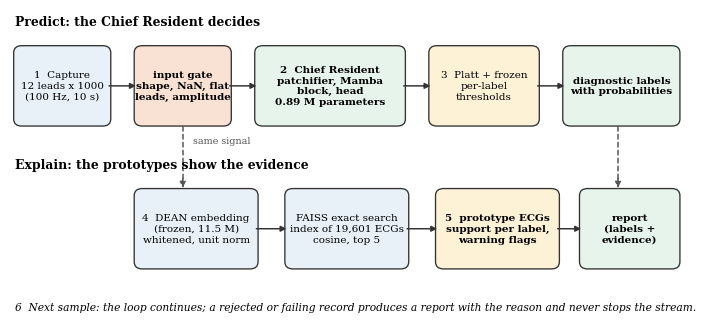

In [7]:
# ---- Figure 1: the deployed system --------------------------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(W2, 3.35)); ax.set_xlim(0, 100); ax.set_ylim(0, 52); ax.axis('off'); ax.grid(False)
def box(x, y, w, h, txt, fc, ec='#333333', fs=6.2, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.25,rounding_size=1.2', fc=fc, ec=ec, lw=0.8))
    ax.text(x + w / 2, y + h / 2, txt, ha='center', va='center', fontsize=fs, fontweight='bold' if bold else 'normal', linespacing=1.25)
def arrow(x0, y0, x1, y1, col='#333333', ls='-'):
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle='-|>', color=col, lw=0.9, ls=ls, shrinkA=0, shrinkB=0))
ax.text(0.5, 50.2, 'Predict: the Chief Resident decides', fontsize=7.4, fontweight='bold', va='center')
box(0.5, 33, 14, 13, '1  Capture\n12 leads x 1000\n(100 Hz, 10 s)', '#E8F1F8')
box(18.5, 33, 14, 13, 'input gate\nshape, NaN, flat\nleads, amplitude', '#F9E1D3', bold=True)
box(36.5, 33, 22, 13, f'2  Chief Resident\npatchifier, Mamba\nblock, head\n{N_PARAMS_CR / 1e6:.2f} M parameters', '#E6F4EC', bold=True)
box(62.5, 33, 16, 13, '3  Platt + frozen\nper-label\nthresholds', '#FDF1D6')
box(82.5, 33, 17, 13, 'diagnostic labels\nwith probabilities', '#E6F4EC', bold=True)
for a_, b_ in [(14.5, 18.5), (32.5, 36.5), (58.5, 62.5), (78.5, 82.5)]: arrow(a_, 39.5, b_, 39.5)
ax.text(0.5, 26.2, 'Explain: the prototypes show the evidence', fontsize=7.4, fontweight='bold', va='center')
box(18.5, 9, 18, 13, f'4  DEAN embedding\n(frozen, {N_PARAMS_DEAN / 1e6:.1f} M)\nwhitened, unit norm', '#E8F1F8')
box(41, 9, 18, 13, f'FAISS exact search\nindex of {len(PIPE.ret.ecg_id):,} ECGs\ncosine, top {CFG["k_proto"]}', '#E8F1F8')
box(63.5, 9, 18, 13, '5  prototype ECGs\nsupport per label,\nwarning flags', '#FDF1D6', bold=True)
box(85, 9, 14.5, 13, 'report\n(labels +\nevidence)', '#E6F4EC', bold=True)
for a_, b_ in [(36.5, 41), (59, 63.5), (81.5, 85)]: arrow(a_, 15.5, b_, 15.5)
ax.plot([25.5, 25.5], [32.8, 22.4], color='#555555', lw=0.9, ls='--'); arrow(25.5, 24, 25.5, 22.4, '#555555', '--')
ax.text(27, 30.2, 'same signal', fontsize=5.8, color='#555555', va='center')
ax.plot([90.5, 90.5], [32.8, 22.4], color='#555555', lw=0.9, ls='--'); arrow(90.5, 24, 90.5, 22.4, '#555555', '--')
ax.text(0.5, 2.2, '6  Next sample: the loop continues; a rejected or failing record produces a report with the reason and never stops the stream.', fontsize=6.4, style='italic', va='center')
save_fig(fig, 'fig01_deployed_system')

## 4. The frozen decision rule
Probabilities are `sigmoid(a_l * logit + b_l)` (Platt map per label), and a label is returned when its probability reaches its own threshold. Both sets of numbers come from fold 9 (Stage 10) and are read, not recomputed, here. Labels with fewer than 10 validation positives were given the pooled threshold, because a threshold fitted on a handful of examples is noise; they are marked in the figure and flagged in the reports.

[ok] the deployed pipeline uses exactly the frozen thresholds and Platt maps
[ok] every threshold lies inside the searched grid and every Platt slope is positive


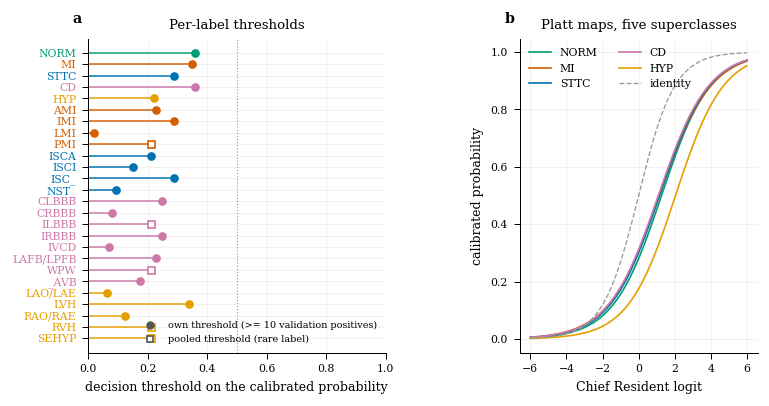

In [8]:
SYS = FZ['systems']['chief_resident']
THR, PA, PB = np.array(SYS['thresholds']), np.array(SYS['platt_a']), np.array(SYS['platt_b'])
REL = np.array(FZ['reliable_val'], bool)
check('the deployed pipeline uses exactly the frozen thresholds and Platt maps', np.allclose(PIPE.thr, THR) and np.allclose(PIPE.a, PA) and np.allclose(PIPE.b, PB))
check('every threshold lies inside the searched grid and every Platt slope is positive', bool(np.all((THR >= min(FZ['grid'])) & (THR <= max(FZ['grid']))) and np.all(PA > 0)))
fig, axs = plt.subplots(1, 2, figsize=(W2, 3.4), gridspec_kw=dict(width_ratios=[1.25, 1], wspace=0.5))
ax = axs[0]
yy = np.arange(26)[::-1]
for y_, l, t_, r_ in zip(yy, LABELS, THR, REL):
    ax.hlines(y_, 0, t_, color=fam_col(l), lw=1.1, alpha=0.8)
    ax.plot(t_, y_, 'o' if r_ else 's', ms=4.2, mfc=fam_col(l) if r_ else 'white', mec=fam_col(l), mew=1.0)
ax.set_yticks(yy); ax.set_yticklabels(LABELS); ax.set_xlabel('decision threshold on the calibrated probability'); ax.set_xlim(0, 1)
ax.axvline(0.5, color='#999999', lw=0.7, ls=':')
for tl, l in zip(ax.get_yticklabels(), LABELS): tl.set_color(fam_col(l))
ax.legend(handles=[Line2D([], [], marker='o', ls='', mfc='#555555', mec='#555555', ms=4, label='own threshold (>= 10 validation positives)'),
                   Line2D([], [], marker='s', ls='', mfc='white', mec='#555555', ms=4, label='pooled threshold (rare label)')], loc='lower right', fontsize=5.8)
ax.set_title('Per-label thresholds'); panel(ax, 'a')
ax = axs[1]
pp = np.linspace(-6, 6, 200)
for l in ('NORM', 'MI', 'STTC', 'CD', 'HYP'):
    j = LABELS.index(l); ax.plot(pp, 1 / (1 + np.exp(-(pp * PA[j] + PB[j]))), color=fam_col(l), label=l)
ax.plot(pp, 1 / (1 + np.exp(-pp)), color='#999999', ls='--', lw=0.8, label='identity')
ax.set_xlabel('Chief Resident logit'); ax.set_ylabel('calibrated probability'); ax.set_title('Platt maps, five superclasses'); ax.legend(ncol=2, loc='upper left'); panel(ax, 'b')
save_fig(fig, 'fig02_decision_rule')

## 5. Deployment settings, fixed on fold 9
Three constants are needed beyond Stage 10, and they are fixed here, on validation data only, with the **train-only** index (folds 1 to 8), so that no validation ECG can find itself among its neighbours:

1. **Amplitude bounds of the input gate** (label-free): the robust scale of a record relative to the training scale. A record outside the range seen on fold 9 (widened by a factor of two) is almost certainly in other units or damaged.
2. **Atypical-ECG threshold** (label-free): the 5th percentile of the similarity between a validation ECG and its nearest prototype. A new ECG below it has no close relative in the index, so its explanation is weak.
3. **Support-to-precision table** (uses fold-9 labels): for every predicted label, how many of the five nearest prototypes carry it, and how often such predictions were right. This turns "3 of 5 prototypes agree" into a measured statement.

In [9]:
t0 = time.time()
VA_REP, AMP_RATIO = [], []
SDv = PIPE.sd[0, :, 0]
for i in range(0, NVA, CFG['cal_bs']):
    xb = get_sig(va_idx[i:i + CFG['cal_bs']])
    VA_REP += PIPE_VAL.predict(xb, explain=True)
    sdl = np.nan_to_num(xb).std(2)
    AMP_RATIO.append(np.nanmedian(np.where(sdl > 1e-6, sdl / SDv[None], np.nan), axis=1))
AMP_RATIO = np.concatenate(AMP_RATIO)
print(f'fold 9 through the pipeline in {time.time() - t0:.0f} s')
TOP1 = np.array([r['prototypes'][0]['similarity'] for r in VA_REP])
PRED = np.array([[l in r['labels'] for l in LABELS] for r in VA_REP])
SUPP = np.array([[sum(l in p['labels'] for p in r['prototypes']) for l in LABELS] for r in VA_REP])
AMP_LO, AMP_HI = float(np.quantile(AMP_RATIO, 0.001) / CFG['amp_margin']), float(np.quantile(AMP_RATIO, 0.999) * CFG['amp_margin'])
SIM_FLAG = float(np.quantile(TOP1, CFG['sim_flag_quantile']))
rows = []
for s in range(CFG['k_proto'] + 1):
    m = PRED & (SUPP == s); n = int(m.sum())
    prec = float(Y_va[m].mean()) if n else None
    rows.append(dict(support=s, n=n, precision=prec, se=float(np.sqrt(prec * (1 - prec) / n)) if n else None, positives=int(Y_va[m].sum()) if n else 0))
SUP_TAB = pd.DataFrame(rows)
SUP_TAB.to_csv(os.path.join(TAB_DIR, 'support_precision_fold9.csv'), index=False)
display_tab = SUP_TAB.copy(); display_tab['precision'] = display_tab['precision'].map(lambda v: '' if v is None or v != v else f'{v:.3f}')
print(display_tab.to_string(index=False))
CALIB = dict(max_nonfinite_fraction=CFG['max_nonfinite_fraction'], flat_std=CFG['flat_std'], max_flat_leads=CFG['max_flat_leads'], amp_lo=AMP_LO, amp_hi=AMP_HI,
             sim_flag=SIM_FLAG, sim_flag_quantile=CFG['sim_flag_quantile'], min_cell=CFG['min_cell'], min_pos=CFG['min_pos'],
             val_positives=[int(v) for v in Y_va.sum(0)], support_table=[{k: (None if (v is None or (isinstance(v, float) and v != v)) else v) for k, v in r.items()} for r in rows],
             k_proto=CFG['k_proto'], source='fold 9 with the train-only index (folds 1-8)', frozen_sha256=sha256(P['frozen']))
json.dump(CALIB, open(os.path.join(WORK, 'deploy_calibration.json'), 'w'), indent=1)
print(f'amplitude bounds {AMP_LO:.3g} .. {AMP_HI:.3g} (fold 9 range {AMP_RATIO.min():.3g} .. {AMP_RATIO.max():.3g}) | atypical below top-1 similarity {SIM_FLAG:.3f} (median {np.median(TOP1):.3f})')
check('fold-9 predictions are finite and every fold-9 record passes the new gate bounds', bool(np.isfinite(TOP1).all()) and bool(((AMP_RATIO >= AMP_LO) & (AMP_RATIO <= AMP_HI)).all()))
tabv = SUP_TAB[SUP_TAB.n >= CFG['min_cell']]
check('precision rises with prototype support (first supported level vs the last)', len(tabv) >= 2 and tabv.precision.iloc[-1] > tabv.precision.iloc[0], f'{tabv.precision.iloc[0]:.3f} -> {tabv.precision.iloc[-1]:.3f}' if len(tabv) >= 2 else 'too few cells', level='warn')
rho = float(pd.Series(tabv.support.values).corr(pd.Series(tabv.precision.values), method='spearman')) if len(tabv) >= 3 else float('nan')
print('Spearman(support, precision) over populated levels:', round(rho, 3))
SVC = HiDMambaService(PIPE, CALIB)
check('the service is built on the frozen configuration', SVC.labels == LABELS and SVC.k == CFG['k_proto'])

fold 9 through the pipeline in 22 s
 support    n precision       se  positives
       0  657     0.198 0.015543        130
       1  673     0.351 0.018394        236
       2  681     0.501 0.019160        341
       3  738     0.630 0.017771        465
       4  879     0.747 0.014655        657
       5 1413     0.881 0.008610       1245
amplitude bounds 0.143 .. 4.77 (fold 9 range 0.218 .. 2.83) | atypical below top-1 similarity 0.478 (median 0.600)
[ok] fold-9 predictions are finite and every fold-9 record passes the new gate bounds
[ok] precision rises with prototype support (first supported level vs the last): 0.198 -> 0.881
Spearman(support, precision) over populated levels: 1.0
[ok] the service is built on the frozen configuration


True

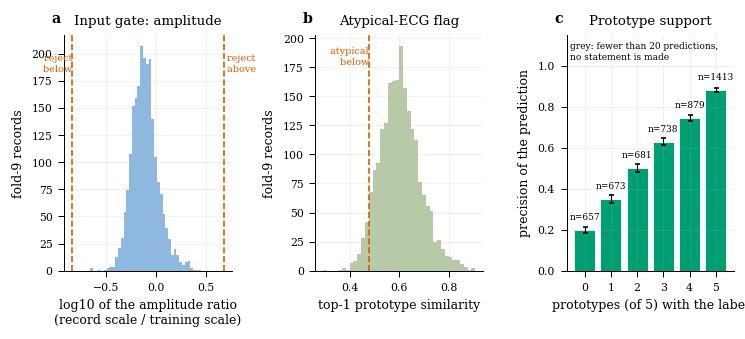

In [10]:
# ---- Figure 3: deployment calibration on fold 9 -------------------------------------------------------------------------------------
fig, axs = plt.subplots(1, 3, figsize=(W2, 2.55), gridspec_kw=dict(wspace=0.5))
ax = axs[0]
ax.hist(np.log10(AMP_RATIO), bins=40, color='#8FB8DE', ec='white', lw=0.3)
for v_, c_ in ((AMP_LO, C_BAD), (AMP_HI, C_BAD)): ax.axvline(np.log10(v_), color=c_, ls='--', lw=1)
ax.set_xlabel('log10 of the amplitude ratio\n(record scale / training scale)'); ax.set_ylabel('fold-9 records'); ax.set_title('Input gate: amplitude'); panel(ax, 'a')
ax.text(np.log10(AMP_LO), ax.get_ylim()[1] * 0.92, ' reject\n below', color=C_BAD, fontsize=5.8, ha='right', va='top'); ax.text(np.log10(AMP_HI), ax.get_ylim()[1] * 0.92, ' reject\n above', color=C_BAD, fontsize=5.8, va='top')
ax = axs[1]
ax.hist(TOP1, bins=40, color='#B8C9A8', ec='white', lw=0.3)
ax.axvline(SIM_FLAG, color=C_BAD, ls='--', lw=1); ax.text(SIM_FLAG, ax.get_ylim()[1] * 0.95, ' atypical\n below', color=C_BAD, fontsize=5.8, ha='right', va='top')
ax.set_xlabel('top-1 prototype similarity'); ax.set_ylabel('fold-9 records'); ax.set_title('Atypical-ECG flag'); panel(ax, 'b')
ax = axs[2]
sh = SUP_TAB[SUP_TAB.n > 0]
cols = [C_OK if n >= CFG['min_cell'] else '#BBBBBB' for n in sh.n]
ax.bar(sh.support, sh.precision, color=cols, ec='white', lw=0.5, yerr=sh.se.fillna(0), error_kw=dict(lw=0.7, capsize=1.5))
for s_, p_, n_ in zip(sh.support, sh.precision, sh.n): ax.text(s_, min(p_ + 0.05, 1.04), f'n={n_}', ha='center', fontsize=5.4)
ax.set_xticks(range(CFG['k_proto'] + 1)); ax.set_ylim(0, 1.15); ax.set_xlabel(f'prototypes (of {CFG["k_proto"]}) with the label'); ax.set_ylabel('precision of the prediction')
ax.set_title('Prototype support'); panel(ax, 'c')
ax.text(0.02, 0.97, 'grey: fewer than %d predictions,\nno statement is made' % CFG['min_cell'], transform=ax.transAxes, fontsize=5.4, va='top')
save_fig(fig, 'fig03_deployment_calibration')

## 6. The input gate on stress tests
A deployed model meets inputs that the benchmark never contained. Fifteen deliberately wrong or damaged versions of one real record are passed through the gate; each has an expected decision written *before* the run (accept, warn: processed with a note, or reject: no prediction). The gate must agree with all of them.

[ok] gate: clean record -> accept: accept
[ok] gate: transposed, (1000, 12) -> warn: warn | array was (samples, leads): transposed
[ok] gate: longer, 1200 samples -> warn: warn | 1200 samples: the first 1000 (10 s) are used
[ok] gate: shorter, 600 samples -> reject: reject | 600 samples: at least 1000 are needed (10 s at 100 Hz)
[ok] gate: 11 leads -> reject: reject | expected 12 leads, got shape (11, 1000)
[ok] gate: 1 % NaN samples -> warn: warn | 1.07% NaN/inf samples set to 0 (as in training)
[ok] gate: 30 % NaN samples -> reject: reject | 30.3% of the samples are NaN/inf (limit 5%)
[ok] gate: inf in 0.1 % of samples -> warn: warn | 0.07% NaN/inf samples set to 0 (as in training)
[ok] gate: 2 flat leads -> warn: warn | 2 flat lead(s): I, II
[ok] gate: 5 flat leads -> reject: reject | 5 flat leads (I, II, III, aVR, aVL); at most 3 are tolerated
[ok] gate: microvolts (x1000) -> reject: reject | signal amplitude is 642x the training scale (accepted 0.14 to 4.8); wr
[ok] gate: volts (x

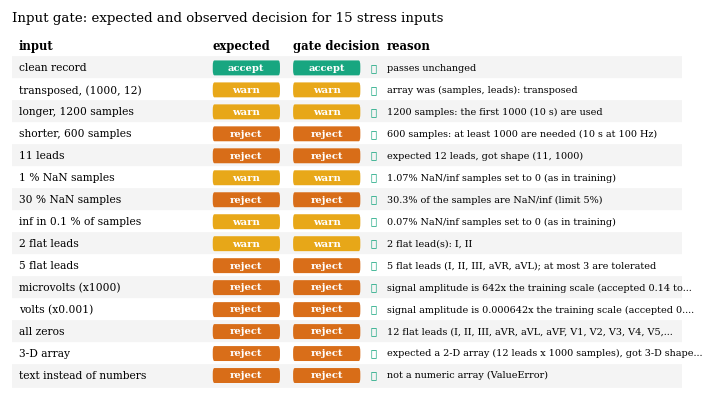

In [11]:
X0 = get_sig(te_idx[:1])[0]
def _nan(frac, seed=1):
    x = X0.copy(); m = np.random.RandomState(seed).rand(*x.shape) < frac; x[m] = np.nan; return x
def _flat(k):
    x = X0.copy(); x[:k] = x[:k].mean(1, keepdims=True); return x
STRESS = OrderedDict([
    ('clean record',              (X0, 'accept')),
    ('transposed, (1000, 12)',    (X0.T.copy(), 'warn')),
    ('longer, 1200 samples',      (np.concatenate([X0, X0[:, :200]], 1), 'warn')),
    ('shorter, 600 samples',      (X0[:, :600].copy(), 'reject')),
    ('11 leads',                  (X0[:11].copy(), 'reject')),
    ('1 % NaN samples',           (_nan(0.01), 'warn')),
    ('30 % NaN samples',          (_nan(0.30), 'reject')),
    ('inf in 0.1 % of samples',   (np.where(np.random.RandomState(2).rand(*X0.shape) < 0.001, np.inf, X0).astype(np.float32), 'warn')),
    ('2 flat leads',              (_flat(2), 'warn')),
    ('5 flat leads',              (_flat(5), 'reject')),
    ('microvolts (x1000)',        (X0 * 1000, 'reject')),
    ('volts (x0.001)',            (X0 * 0.001, 'reject')),
    ('all zeros',                 (np.zeros_like(X0), 'reject')),
    ('3-D array',                 (X0[None].copy(), 'reject')),
    ('text instead of numbers',   ('not an ECG', 'reject')),
])
GATE_ROWS = []
for name, (arr, expect) in STRESS.items():
    xs, st, iss = validate_ecg(arr, SVC.sd, CALIB)
    GATE_ROWS.append(dict(input=name, expected=expect, decision=st, reason='; '.join(iss) if iss else 'passes unchanged'))
    check(f'gate: {name} -> {expect}', st == expect, st + ('' if not iss else ' | ' + iss[0][:70]))
    if st != 'reject': assert xs.shape == (12, 1000) and xs.dtype == np.float32 and np.isfinite(xs).all()
GATE = pd.DataFrame(GATE_ROWS); GATE.to_csv(os.path.join(TAB_DIR, 'input_gate_stress_tests.csv'), index=False)
r_ = SVC.analyse('not an ECG', 'bad-text'); check('a report (not an exception) is returned for unusable input', r_['status'] == 'reject' and r_['labels'] == [])
r_ = SVC.analyse(None, 'bad-none'); check('None input is rejected with a reason', r_['status'] == 'reject' and len(r_['issues']) == 1)

fig, ax = plt.subplots(figsize=(W2, 3.9)); ax.axis('off'); ax.grid(False); ax.set_xlim(0, 100); ax.set_ylim(0, len(GATE) + 1.4)
for x_, t_ in ((1, 'input'), (30, 'expected'), (42, 'gate decision'), (56, 'reason')): ax.text(x_, len(GATE) + 0.75, t_, fontweight='bold', fontsize=7, va='center')
for i, r in GATE.iterrows():
    y = len(GATE) - i - 0.25
    ax.axhspan(y - 0.5, y + 0.5, color='#F4F4F4' if i % 2 == 0 else 'white', zorder=0)
    ax.text(1, y, r.input, va='center', fontsize=6.4)
    for x_, v in ((30, r.expected), (42, r.decision)):
        ax.add_patch(FancyBboxPatch((x_, y - 0.32), 10, 0.64, boxstyle='round,pad=0.02,rounding_size=0.25', fc=STATUS_COL[v], ec='none', alpha=0.9))
        ax.text(x_ + 5, y, v, color='white', ha='center', va='center', fontsize=6, fontweight='bold')
    txt = r.reason if len(r.reason) <= 64 else r.reason[:61] + '...'
    ax.text(56, y, txt, va='center', fontsize=5.8)
    ax.text(54, y, '✓' if r.expected == r.decision else '✗', va='center', ha='center', fontsize=6, fontweight='bold', color=C_OK if r.expected == r.decision else C_BAD)
ax.set_title('Input gate: expected and observed decision for 15 stress inputs', fontsize=8, loc='left')
save_fig(fig, 'fig04_input_gate')

## 7. The incoming stream
`stream_n` records of the held-out fold are fed **one at a time** to `SVC.stream(...)`, a generator over a capture function, exactly as a live system would call it. Every 20th item is replaced by one of the damaged inputs of Section 6, to show the loop surviving them. The first calls are warm-up (library loading, GPU initialisation) and are not timed.

For records of fold 10 the output is compared with what Stage 10 computed for the *same* ECG in batches of 128 on the evaluation path (training-time scan). Agreement shows that the service, the single-record path and the library scan reproduce the evaluated model, so the Stage-10 test result describes what is deployed.

In [12]:
for i in range(CFG['warm']): SVC.analyse(get_sig(va_idx[i:i + 1])[0], f'warm{i}')
rng = np.random.RandomState(CFG['seed'])
STREAM_N = min(CFG['stream_n'], NTE)
SEL = rng.choice(te_idx, size=STREAM_N, replace=False)
BAD_KINDS = [k for k in STRESS if k != 'clean record']
def capture():
    """Stand-in for the recorder: yields (sample_id, kind, array) one at a time."""
    n_bad = 0
    for i, r in enumerate(SEL):
        if i % 20 == 19:
            k = BAD_KINDS[n_bad % len(BAD_KINDS)]; n_bad += 1
            yield f'stress{n_bad:02d}', k, STRESS[k][0]
        yield f'ecg{int(ecg_id[r])}', 'clean', sig[r]
KIND = {}
def source():
    for sid, kind, arr in capture():
        KIND[sid] = kind
        yield sid, arr
t0 = time.time()
REPORTS = list(SVC.stream(source()))
STREAM_S = time.time() - t0
print(f'{len(REPORTS)} items in {STREAM_S:.1f} s ({1e3 * STREAM_S / len(REPORTS):.0f} ms per item including capture)')
check('the loop returned one report per incoming item, in order', len(REPORTS) == len(KIND) and [r['sample_id'] for r in REPORTS] == list(KIND))
exp_status = {sid: ('accept' if k == 'clean' else STRESS[k][1]) for sid, k in KIND.items()}
check('every stress item in the stream got the decision of Section 6', all(r['status'] == exp_status[r['sample_id']] for r in REPORTS if KIND[r['sample_id']] != 'clean'))
check('no clean record was rejected or raised an error', all(r['status'] in ('accept', 'warn') for r in REPORTS if KIND[r['sample_id']] == 'clean'))
LOG = pd.DataFrame([dict(sample_id=r['sample_id'], kind=KIND[r['sample_id']], status=r['status'], n_labels=len(r['labels']), labels=' '.join(r['labels']),
                         top1_similarity=r.get('top1_similarity', np.nan), n_flags=len(r['flags']), min_support=min([e['support'] for e in r['label_evidence']], default=np.nan),
                         latency_ms=r['latency_ms'], **{f't_{k}': v for k, v in r['timings'].items()}) for r in REPORTS])
LOG.to_csv(os.path.join(WORK, 'stream_log.csv'), index=False)
print(LOG.status.value_counts().to_dict())

210 items in 18.6 s (88 ms per item including capture)
[ok] the loop returned one report per incoming item, in order
[ok] every stress item in the stream got the decision of Section 6
[ok] no clean record was rejected or raised an error
{'accept': 200, 'warn': 5, 'reject': 5}


[ok] Stage-10 test files use the same thresholds as the frozen configuration
records compared with Stage 10: 200
{'n': 200, 'max_abs_dp': 6.773275713078952e-07, 'median_abs_dp': 1.269055384541494e-09, 'label_sets_identical': 1.0, 'n_near_threshold': 1, 'top1_neighbour_identical': 1.0, 'mean_neighbour_overlap': 1.0, 'max_abs_dsim': 0.00016075372695922852}
[ok] single-record probabilities equal the Stage-10 batch probabilities (max abs difference < 1e-3): 6.77e-07
[ok] diagnostic label sets are identical to Stage 10 (records not on a threshold): 1.0000
[ok] the nearest prototype is the same as in Stage 10 for at least 95% of records: 1.000
[ok] at least 95% of the five prototypes coincide with Stage 10 (fp16 DEAN embeddings can reorder near-ties): 1.000


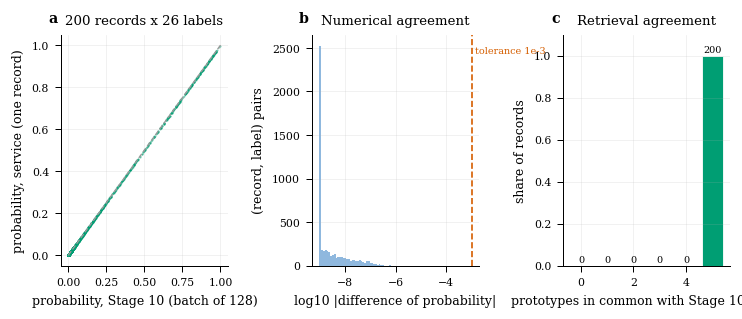

In [13]:
# ---- agreement with the batch evaluation of Stage 10 ----------------------------------------------------------------------------
P10 = dict(np.load(find_one('test_predictions.npz', 'of Stage 10 (hidmamba-stage10)'), allow_pickle=True)); E10 = dict(np.load(find_one('test_explanations.npz', 'of Stage 10 (hidmamba-stage10)'), allow_pickle=True))
check('Stage-10 test files use the same thresholds as the frozen configuration', np.allclose(P10['thr_cr'], THR))
r10 = {int(e): i for i, e in enumerate(P10['ecg_id'])}
CMP = [(r, r10[int(r['sample_id'][3:])]) for r in REPORTS if KIND[r['sample_id']] == 'clean' and r['status'] != 'reject' and int(r['sample_id'][3:]) in r10]
print('records compared with Stage 10:', len(CMP))
PS = np.array([[r['probabilities'][l] for l in LABELS] for r, _ in CMP]); P0 = np.array([P10['p_chief_resident'][j] for _, j in CMP])
DP = np.abs(PS - P0)
near = (np.abs(P0 - THR[None]) < 1e-4).any(1)
same_set = np.array([set(r['labels']) == {l for l, p_, t_ in zip(LABELS, P10['p_chief_resident'][j], THR) if p_ >= t_} for r, j in CMP])
NB_SVC = np.array([[p['ecg_id'] for p in r['prototypes']] for r, _ in CMP]); NB_10 = np.array([E10['neighbour_ecg_id'][j][:CFG['k_proto']] for _, j in CMP])
SIM_SVC = np.array([[p['similarity'] for p in r['prototypes']] for r, _ in CMP]); SIM_10 = np.array([E10['neighbour_similarity'][j][:CFG['k_proto']] for _, j in CMP])
OVL = np.array([len(set(a) & set(b)) for a, b in zip(NB_SVC, NB_10)])
CONS = dict(n=len(CMP), max_abs_dp=float(DP.max()), median_abs_dp=float(np.median(DP)), label_sets_identical=float(same_set[~near].mean()) if (~near).any() else float('nan'),
            n_near_threshold=int(near.sum()), top1_neighbour_identical=float((NB_SVC[:, 0] == NB_10[:, 0]).mean()), mean_neighbour_overlap=float(OVL.mean() / CFG['k_proto']),
            max_abs_dsim=float(np.abs(SIM_SVC - SIM_10).max()))
print(CONS)
check('single-record probabilities equal the Stage-10 batch probabilities (max abs difference < 1e-3)', len(CMP) > 0 and CONS['max_abs_dp'] < 1e-3, f'{CONS["max_abs_dp"]:.2e}')
check('diagnostic label sets are identical to Stage 10 (records not on a threshold)', len(CMP) > 0 and CONS['label_sets_identical'] == 1.0, f'{CONS["label_sets_identical"]:.4f}')
check('the nearest prototype is the same as in Stage 10 for at least 95% of records', len(CMP) > 0 and CONS['top1_neighbour_identical'] >= 0.95, f'{CONS["top1_neighbour_identical"]:.3f}', level='warn')
check('at least 95% of the five prototypes coincide with Stage 10 (fp16 DEAN embeddings can reorder near-ties)', len(CMP) > 0 and CONS['mean_neighbour_overlap'] >= 0.95, f'{CONS["mean_neighbour_overlap"]:.3f}', level='warn')

fig, axs = plt.subplots(1, 3, figsize=(W2, 2.5), gridspec_kw=dict(wspace=0.5))
ax = axs[0]
ax.plot([0, 1], [0, 1], color='#999999', lw=0.8, ls='--'); ax.scatter(P0.ravel(), PS.ravel(), s=1.5, c=C_OK, alpha=0.5, rasterized=True, lw=0)
ax.set_xlabel('probability, Stage 10 (batch of 128)'); ax.set_ylabel('probability, service (one record)'); ax.set_title(f'{len(CMP)} records x 26 labels'); panel(ax, 'a')
ax = axs[1]
v = np.clip(DP.ravel(), 1e-9, None); ax.hist(np.log10(v), bins=40, color='#8FB8DE', ec='white', lw=0.3)
ax.axvline(-3, color=C_BAD, ls='--', lw=1); ax.text(-3, ax.get_ylim()[1] * 0.95, ' tolerance 1e-3', color=C_BAD, fontsize=5.8, va='top')
ax.set_xlabel('log10 |difference of probability|'); ax.set_ylabel('(record, label) pairs'); ax.set_title('Numerical agreement'); panel(ax, 'b')
ax = axs[2]
cnt = np.bincount(OVL, minlength=CFG['k_proto'] + 1)
ax.bar(range(CFG['k_proto'] + 1), cnt / max(cnt.sum(), 1), color=['#BBBBBB'] * CFG['k_proto'] + [C_OK], ec='white', lw=0.5)
for i, c_ in enumerate(cnt): ax.text(i, c_ / max(cnt.sum(), 1) + 0.015, str(c_), ha='center', fontsize=5.8)
ax.set_xlabel(f'prototypes in common with Stage 10 (of {CFG["k_proto"]})'); ax.set_ylabel('share of records'); ax.set_title('Retrieval agreement'); ax.set_ylim(0, 1.1); panel(ax, 'c')
save_fig(fig, 'fig05_agreement_with_stage10')

## 8. Latency and monitoring of the stream
The end-to-end time of one record is split into the part that produces the **diagnosis** (steps 1 to 3: normalisation, Chief Resident, calibration) and the part that produces the **explanation** (step 4: the DEAN embedding and the FAISS search). Stage 10 found that the DEAN pass dominates the end-to-end time; it is measured here again on single records through the service.

            median   p95    p99    max
core_ms        8.3   9.2   10.5   10.6
explain_ms    77.6  81.7   89.5  119.5
latency_ms    89.9  98.6  113.1  148.7
device cuda | n = 205 single-record calls | throughput 11.1 records/s at the median
[ok] every processed record produced finite latency components
[ok] the end-to-end time is at least the sum of its parts: min other 0.33 ms


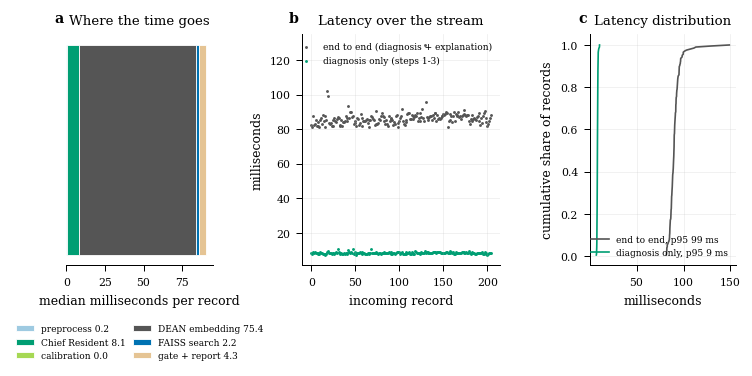

In [14]:
OKL = LOG[LOG.status.isin(['accept', 'warn'])].copy()
for c in ('t_preprocess', 't_chief_resident', 't_calibrate', 't_dean_embedding', 't_retrieval', 't_assemble'): assert c in OKL.columns, c
OKL['core_ms'] = OKL.t_preprocess + OKL.t_chief_resident + OKL.t_calibrate
OKL['explain_ms'] = OKL.t_dean_embedding + OKL.t_retrieval
OKL['other_ms'] = OKL.latency_ms - OKL.core_ms - OKL.explain_ms
q = lambda s, p: float(np.percentile(s, p))
LAT = {k: dict(median=q(OKL[k], 50), p95=q(OKL[k], 95), p99=q(OKL[k], 99), max=float(OKL[k].max())) for k in ('core_ms', 'explain_ms', 'latency_ms')}
print(pd.DataFrame(LAT).T.round(1).to_string())
print(f'device {dev} | n = {len(OKL)} single-record calls | throughput {1e3 / LAT["latency_ms"]["median"]:.1f} records/s at the median')
check('every processed record produced finite latency components', bool(np.isfinite(OKL[['core_ms', 'explain_ms', 'latency_ms']].values).all()))
check('the end-to-end time is at least the sum of its parts', bool((OKL.other_ms > -1.0).all()), f'min other {OKL.other_ms.min():.2f} ms')
pd.DataFrame(LAT).T.to_csv(os.path.join(TAB_DIR, 'stream_latency_ms.csv'))

fig, axs = plt.subplots(1, 3, figsize=(W2, 2.5), gridspec_kw=dict(wspace=0.55, width_ratios=[1.0, 1.35, 1.0]))
ax = axs[0]
comp = [('preprocess', 't_preprocess', '#9ECAE1'), ('Chief Resident', 't_chief_resident', C_OK), ('calibration', 't_calibrate', '#A6D854'),
        ('DEAN embedding', 't_dean_embedding', '#555555'), ('FAISS search', 't_retrieval', '#0072B2'), ('gate + report', 'other_ms', '#E5C494')]
left = 0.0
for nm, col, c_ in comp:
    v_ = float(OKL[col].median()); ax.barh(0, v_, left=left, color=c_, ec='white', lw=0.5, label=f'{nm} {v_:.1f}'); left += v_
ax.set_yticks([]); ax.set_xlabel('median milliseconds per record'); ax.set_title('Where the time goes'); ax.legend(fontsize=5.4, loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=2, columnspacing=0.8)
ax.grid(False); ax.spines['left'].set_visible(False); panel(ax, 'a')
ax = axs[1]
xs_ = np.arange(len(OKL))
ax.scatter(xs_, OKL.explain_ms + OKL.core_ms, s=3, color='#555555', label='end to end (diagnosis + explanation)', lw=0, rasterized=True)
ax.scatter(xs_, OKL.core_ms, s=3, color=C_OK, label='diagnosis only (steps 1-3)', lw=0, rasterized=True)
ax.set_xlabel('incoming record'); ax.set_ylabel('milliseconds'); ax.set_title('Latency over the stream'); ax.legend(fontsize=5.4, loc='upper right'); panel(ax, 'b')
ax = axs[2]
for k, c_, nm in (('latency_ms', '#555555', 'end to end'), ('core_ms', C_OK, 'diagnosis only')):
    v_ = np.sort(OKL[k].values); ax.plot(v_, np.arange(1, len(v_) + 1) / len(v_), color=c_, label=f'{nm}, p95 {q(v_, 95):.0f} ms')
ax.set_xlabel('milliseconds'); ax.set_ylabel('cumulative share of records'); ax.set_title('Latency distribution'); ax.legend(fontsize=5.4, loc='lower right'); panel(ax, 'c')
save_fig(fig, 'fig06_stream_latency')

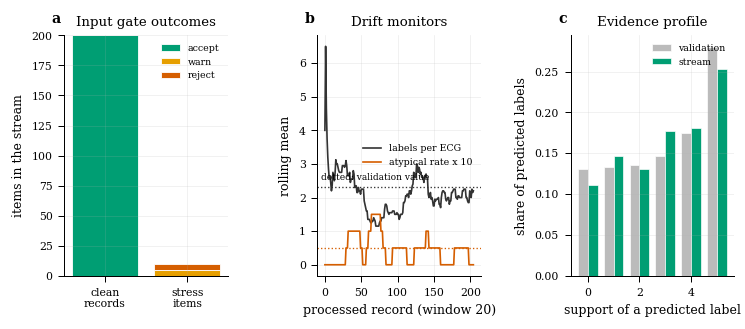

{'status_clean': {'accept': 200}, 'status_stress': {'warn': 5, 'reject': 5}, 'mean_labels_stream': 2.097560975609756, 'mean_labels_val': 2.309207512597343, 'atypical_rate_stream': 0.04390243902439024, 'atypical_rate_val': 0.050389372423270726, 'support_share_stream': [0.11162790697674418, 0.14651162790697675, 0.13023255813953488, 0.17674418604651163, 0.1813953488372093, 0.2534883720930233], 'support_share_val': [0.13033128347550088, 0.1335052568934735, 0.13509224360245983, 0.1463995239039873, 0.17437016464987107, 0.2803015274747074]}


In [15]:
# ---- stream monitoring: what a deployed system should watch -----------------------------------------------------------------------
GOOD = [r for r in REPORTS if r['status'] in ('accept', 'warn')]
ST_ORDER = ['accept', 'warn', 'reject', 'error']
cnt_clean = Counter(r['status'] for r in REPORTS if KIND[r['sample_id']] == 'clean'); cnt_bad = Counter(r['status'] for r in REPORTS if KIND[r['sample_id']] != 'clean')
nlab = np.array([len(r['labels']) for r in GOOD]); atyp = np.array([r['top1_similarity'] < SIM_FLAG for r in GOOD], float)
sup_stream = Counter(e['support'] for r in GOOD for e in r['label_evidence'])
sup_fold9 = np.array([int((PRED & (SUPP == s)).sum()) for s in range(CFG['k_proto'] + 1)])
sup_stream_a = np.array([sup_stream.get(s, 0) for s in range(CFG['k_proto'] + 1)])
roll = lambda v, w=20: np.array([v[max(0, i - w + 1):i + 1].mean() for i in range(len(v))])
fig, axs = plt.subplots(1, 3, figsize=(W2, 2.6), gridspec_kw=dict(wspace=0.55))
ax = axs[0]
bottoms = np.zeros(2)
for s in ST_ORDER:
    vals = np.array([cnt_clean.get(s, 0), cnt_bad.get(s, 0)], float)
    if vals.sum() == 0: continue
    ax.bar([0, 1], vals, bottom=bottoms, color=STATUS_COL[s], ec='white', lw=0.5, label=s); bottoms += vals
ax.set_xticks([0, 1]); ax.set_xticklabels(['clean\nrecords', 'stress\nitems']); ax.set_ylabel('items in the stream'); ax.set_title('Input gate outcomes'); ax.legend(fontsize=5.6); panel(ax, 'a')
ax = axs[1]
ax.plot(roll(nlab), color=C_INK, label='labels per ECG'); ax.axhline(PRED.sum(1).mean(), color=C_INK, ls=':', lw=0.8)
ax.plot(roll(atyp) * 10, color=C_BAD, label='atypical rate x 10'); ax.axhline(CFG['sim_flag_quantile'] * 10, color=C_BAD, ls=':', lw=0.8)
ax.set_xlabel('processed record (window 20)'); ax.set_ylabel('rolling mean'); ax.set_title('Drift monitors'); ax.legend(fontsize=5.6, loc='center right'); panel(ax, 'b')
ax.text(0.02, 0.4, 'dotted: validation value', transform=ax.transAxes, fontsize=5.4)
ax = axs[2]
wd = 0.38; xx = np.arange(CFG['k_proto'] + 1)
ax.bar(xx - wd / 2, sup_fold9 / max(sup_fold9.sum(), 1), wd, color='#BBBBBB', label='validation', ec='white', lw=0.4)
ax.bar(xx + wd / 2, sup_stream_a / max(sup_stream_a.sum(), 1), wd, color=C_OK, label='stream', ec='white', lw=0.4)
ax.set_xlabel('support of a predicted label'); ax.set_ylabel('share of predicted labels'); ax.set_title('Evidence profile'); ax.legend(fontsize=5.6, loc='upper right'); panel(ax, 'c')
save_fig(fig, 'fig07_stream_monitoring')
MON = dict(status_clean=dict(cnt_clean), status_stress=dict(cnt_bad), mean_labels_stream=float(nlab.mean()), mean_labels_val=float(PRED.sum(1).mean()),
           atypical_rate_stream=float(atyp.mean()), atypical_rate_val=float((TOP1 < SIM_FLAG).mean()), support_share_stream=(sup_stream_a / max(sup_stream_a.sum(), 1)).tolist(), support_share_val=(sup_fold9 / max(sup_fold9.sum(), 1)).tolist())
print(MON)

## 9. One sample, step by step, and the report cards
Three records of the stream are shown in full. They are chosen **from the model's own output only**: the most confident multi-label prediction, a normal ECG, and the prediction with the weakest prototype evidence. No example is chosen by whether it was right; the PTB-XL annotation is printed beside each for reading, and no metric is computed from it. For the first example the six steps of the synopsis are executed one by one on the components of the pipeline and compared with what `analyse()` returned.

In [16]:
CLEAN = [r for r in GOOD if KIND[r['sample_id']] == 'clean']
def pick(cands, key, exclude):
    cands = [r for r in cands if r['sample_id'] not in exclude]
    return max(cands, key=key) if cands else None
used = set()
exA = pick([r for r in CLEAN if len(r['labels']) >= 2], lambda r: min(e['probability'] for e in r['label_evidence']), used) or pick([r for r in CLEAN if r['labels']], lambda r: max(e['probability'] for e in r['label_evidence']), used)
used.add(exA['sample_id'])
exB = pick([r for r in CLEAN if r['labels'] == ['NORM']], lambda r: r['probabilities']['NORM'], used) or pick([r for r in CLEAN if r['labels']], lambda r: -len(r['labels']), used)
used.add(exB['sample_id'])
exC = pick([r for r in CLEAN if r['labels']], lambda r: -(min(e['support'] for e in r['label_evidence']) * 10 + r['top1_similarity']), used)
EXAMPLES = [('A', 'most confident multi-label prediction', exA), ('B', 'normal ECG', exB), ('C', 'weakest prototype evidence', exC)][:CFG['n_examples']]
for tag, why, r in EXAMPLES: print(tag, why, '->', r['sample_id'], r['labels'])

rA = exA; eA = int(rA['sample_id'][3:]); xA = get_sig(ROW_OF[eA])
print('\n=== the six steps on example A (ECG %d) ===' % eA)
print(f'1  capture: array {xA.shape} {xA.dtype}, per-lead mean {xA.mean():+.3f} mV, std {xA.std():.3f} mV; gate -> {validate_ecg(xA, SVC.sd, CALIB)[1]}')
with torch.no_grad():
    xt = torch.from_numpy((np.nan_to_num(xA[None]) - PIPE.mu) / PIPE.sd).to(dev)
    lg = PIPE.cr(xt).float().cpu().numpy()[0].astype(np.float64)
    ctx = torch.autocast('cuda', dtype=torch.float16) if PIPE.amp else torch.autocast('cpu', enabled=False)
    with ctx: zA = PIPE.dean(xt).float().mean(1).cpu().numpy()
print(f'2  Chief Resident: normalised input {tuple(xt.shape)} -> {len(lg)} logits; largest: ' + ', '.join(f'{LABELS[j]} {lg[j]:+.2f}' for j in np.argsort(-lg)[:4]))
pA = 1 / (1 + np.exp(-(lg * PA + PB))); posA = pA >= THR
print('3  calibrated probabilities and frozen thresholds: ' + ', '.join(f'{LABELS[j]} p={pA[j]:.2f} (thr {THR[j]:.2f})' for j in np.where(posA)[0]) + ('' if posA.any() else 'none above threshold'))
DA, IA = PIPE.ret.search(zA, CFG['k_proto'])
print(f'4  DEAN embedding {zA.shape[1]}-d (norm {np.linalg.norm(zA):.2f}) -> FAISS top {CFG["k_proto"]}: ' + ', '.join(f'{int(PIPE.ret.ecg_id[i])} ({d:.3f})' for i, d in zip(IA[0], DA[0])))
print('5  report:'); print(render_report(rA, reference_labels(eA)))
check('the step-by-step execution equals the service report (labels, probabilities, prototypes)',
      [LABELS[j] for j in np.where(posA)[0]] == rA['labels'] and np.allclose([rA['probabilities'][l] for l in LABELS], pA, atol=1e-6) and [int(PIPE.ret.ecg_id[i]) for i in IA[0]] == [p['ecg_id'] for p in rA['prototypes']])
print('6  next sample: the stream loop of Section 7 has just done this for', len(REPORTS), 'items')

A most confident multi-label prediction -> ecg16152 ['MI', 'IMI']
B normal ECG -> ecg1311 ['NORM']
C weakest prototype evidence -> ecg1753 ['STTC', 'IVCD', '_AVB']

=== the six steps on example A (ECG 16152) ===
1  capture: array (12, 1000) float32, per-lead mean +0.006 mV, std 0.791 mV; gate -> accept
2  Chief Resident: normalised input (1, 12, 1000) -> 26 logits; largest: IMI +5.30, MI +4.75, ISCI +0.79, AMI +0.28
3  calibrated probabilities and frozen thresholds: MI p=0.93 (thr 0.35), IMI p=0.93 (thr 0.29)
4  DEAN embedding 256-d (norm 12.59) -> FAISS top 5: 11018 (0.671), 2591 (0.639), 16273 (0.619), 21086 (0.619), 19646 (0.614)
5  report:
ECG ecg16152   input: ACCEPT
  diagnostic labels: MI, IMI
    MI         p=0.93 (threshold 0.35)  3/5 nearest prototypes carry it; precision at this support on validation: 63%
    IMI        p=0.93 (threshold 0.29)  3/5 nearest prototypes carry it; precision at this support on validation: 63%
  nearest prototype ECGs:
    1. ecg 11018  similarity

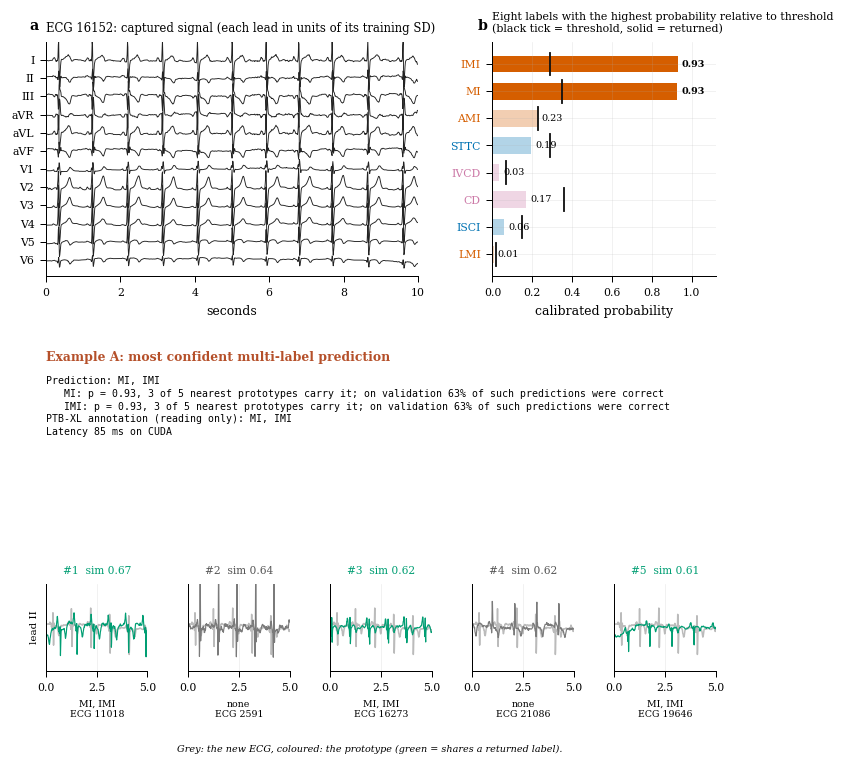

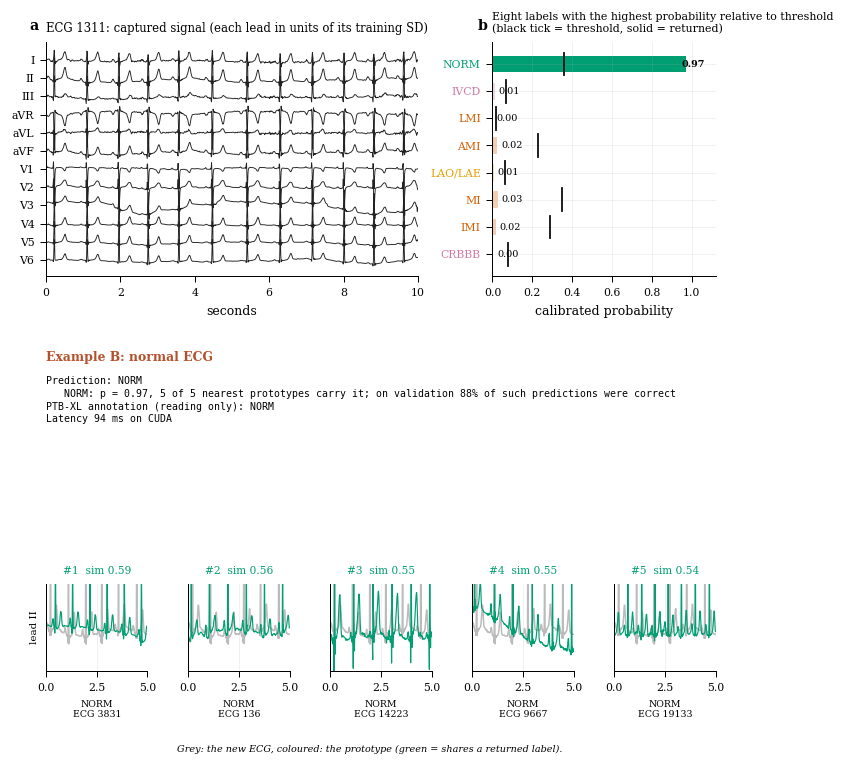

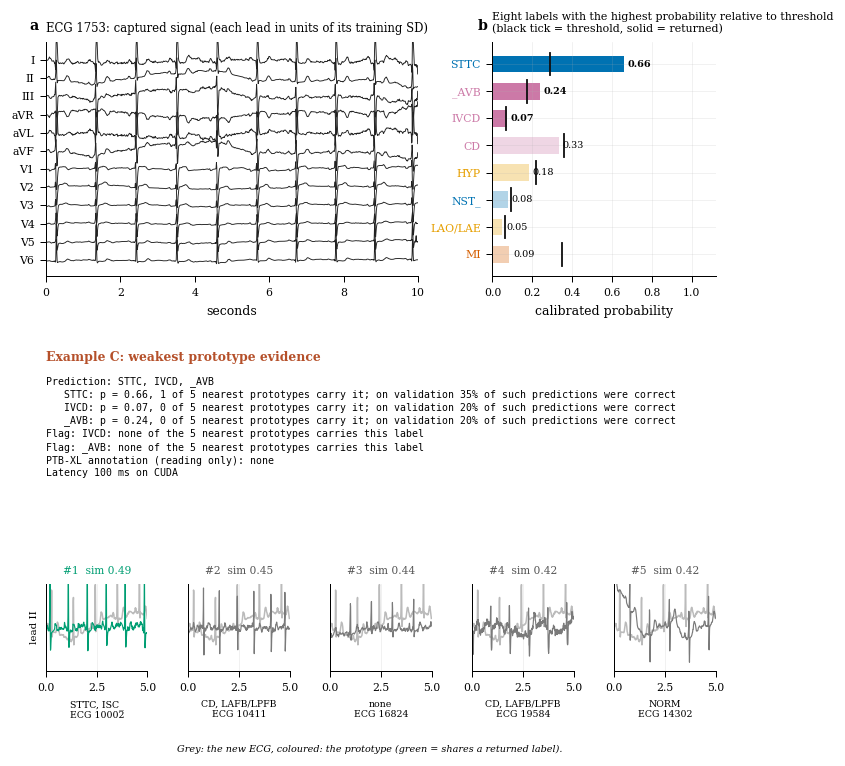

### example A: most confident multi-label prediction
ECG ecg16152   input: ACCEPT
  diagnostic labels: MI, IMI
    MI         p=0.93 (threshold 0.35)  3/5 nearest prototypes carry it; precision at this support on validation: 63%
    IMI        p=0.93 (threshold 0.29)  3/5 nearest prototypes carry it; precision at this support on validation: 63%
  nearest prototype ECGs:
    1. ecg 11018  similarity 0.671  labels: MI, IMI
    2. ecg 2591  similarity 0.639  labels: none
    3. ecg 16273  similarity 0.619  labels: MI, IMI
    4. ecg 21086  similarity 0.619  labels: none
    5. ecg 19646  similarity 0.614  labels: MI, IMI
  reference annotation: MI, IMI
  latency 85 ms

### example B: normal ECG
ECG ecg1311   input: ACCEPT
  diagnostic labels: NORM
    NORM       p=0.97 (threshold 0.36)  5/5 nearest prototypes carry it; precision at this support on validation: 88%
  nearest prototype ECGs:
    1. ecg 3831  similarity 0.588  labels: NORM
    2. ecg 136  similarity 0.564  labels: NORM
    3.

In [17]:
def card(rep, tag, why, name):
    e = int(rep['sample_id'][3:]); x = get_sig(ROW_OF[e]); ref = reference_labels(e)
    fig = plt.figure(figsize=(W2, 6.1))
    g0 = GridSpec(1, 5, figure=fig, top=0.97, bottom=0.65, wspace=1.0); g1 = GridSpec(1, 1, figure=fig, top=0.52, bottom=0.31); g2 = GridSpec(1, 5, figure=fig, top=0.23, bottom=0.11, wspace=0.4)
    ax = fig.add_subplot(g0[0, :3]); t = np.arange(1000) / 100.0
    mu_, sd_ = PIPE.mu[0, :, 0], PIPE.sd[0, :, 0]
    for i in range(12):
        ax.plot(t, 11 - i + np.clip((x[i] - mu_[i]) / sd_[i], -4, 4) * 0.28, color='#222222', lw=0.55)
    ax.set_yticks(11 - np.arange(12)); ax.set_yticklabels(LEAD_NAMES); ax.set_xlim(0, 10); ax.set_ylim(-0.9, 12); ax.set_xlabel('seconds'); ax.grid(axis='x'); ax.grid(axis='y', visible=False)
    ax.set_title(f'ECG {e}: captured signal (each lead in units of its training SD)', fontsize=7, loc='left'); panel(ax, 'a')
    ax = fig.add_subplot(g0[0, 3:])
    pr = np.array([rep['probabilities'][l] for l in LABELS]); sel = np.argsort(-(pr / THR))[:8][::-1]
    for y_, j in enumerate(sel):
        on = pr[j] >= THR[j]; l = LABELS[j]
        ax.barh(y_, pr[j], color=fam_col(l), alpha=1.0 if on else 0.3, ec='none', height=0.62)
        ax.plot([THR[j], THR[j]], [y_ - 0.42, y_ + 0.42], color='#111111', lw=1.1)
        ax.text(min(pr[j], 0.93) + 0.02, y_, f'{pr[j]:.2f}', va='center', fontsize=5.8, fontweight='bold' if on else 'normal')
    ax.set_yticks(range(len(sel))); ax.set_yticklabels([LABELS[j] for j in sel]); ax.set_xlim(0, 1.12); ax.set_xlabel('calibrated probability')
    for tl, j in zip(ax.get_yticklabels(), sel): tl.set_color(fam_col(LABELS[j]))
    ax.set_title('Eight labels with the highest probability relative to threshold\n(black tick = threshold, solid = returned)', fontsize=6.6, loc='left'); panel(ax, 'b')
    ax = fig.add_subplot(g1[0, 0]); ax.axis('off'); ax.grid(False); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    import textwrap
    L = textwrap.wrap('Prediction: ' + (', '.join(rep['labels']) if rep['labels'] else 'no label above its threshold'), 105)[:2]
    for ev in rep['label_evidence']:
        hp = '' if ev['historical_precision'] is None else f'; on validation {100 * ev["historical_precision"]:.0f}% of such predictions were correct'
        L.append(f'   {ev["label"]}: p = {ev["probability"]:.2f}, {ev["support"]} of {ev["k"]} nearest prototypes carry it{hp}')
    L += [f'Flag: {f}' for f in rep['flags']]
    L.append('PTB-XL annotation (reading only): ' + (', '.join(ref) if ref else 'none'))
    L.append(f'Latency {rep["latency_ms"]:.0f} ms on {dev.type.upper()}')
    ax.text(0.0, 0.97, '\n'.join(L[:11]), va='top', ha='left', fontsize=5.9, family='monospace', linespacing=1.35)
    ax.set_title(f'Example {tag}: {why}', fontsize=7.4, fontweight='bold', loc='left', color='#B5502A')
    pl = set(rep['labels'])
    for j, p in enumerate(rep['prototypes'][:5]):
        ax = fig.add_subplot(g2[0, j]); xp = get_sig(ROW_OF[p['ecg_id']]); s = slice(0, 500)
        ax.plot(np.arange(500) / 100.0, (x[1] - mu_[1])[s] / sd_[1], color='#BBBBBB', lw=0.9)
        share = bool(pl & set(p['labels'])) if pl else False
        ax.plot(np.arange(500) / 100.0, (xp[1] - mu_[1])[s] / sd_[1], color=C_OK if share else '#7A7A7A', lw=0.7)
        ax.set_ylim(-4.2, 4.2); ax.set_xlim(0, 5); ax.set_xticks([0, 2.5, 5]); ax.set_yticks([])
        ax.set_title(f'#{j + 1}  sim {p["similarity"]:.2f}', fontsize=6.4, color=C_OK if share else '#555555')
        lab = ', '.join(p['labels']) if p['labels'] else 'none'
        ax.set_xlabel((lab if len(lab) <= 20 else lab[:18] + '..') + f'\nECG {p["ecg_id"]}', fontsize=5.6)
        if j == 0: ax.set_ylabel('lead II', fontsize=6.2)
    fig.text(0.5, 0.0, 'Grey: the new ECG, coloured: the prototype (green = shares a returned label).', ha='center', fontsize=5.8, style='italic')
    save_fig(fig, name)
for (tag, why, rep), nm in zip(EXAMPLES, ('fig08_report_card_A', 'fig09_report_card_B', 'fig10_report_card_C')): card(rep, tag, why, nm)
with open(os.path.join(WORK, 'example_reports.txt'), 'w') as f:
    for tag, why, rep in EXAMPLES: f.write(f'### example {tag}: {why}\n' + render_report(rep, reference_labels(int(rep['sample_id'][3:]))) + '\n\n')
    bad = next((r for r in REPORTS if r['status'] == 'reject'), None)
    if bad: f.write('### a rejected input\n' + render_report(bad) + '\n')
print(open(os.path.join(WORK, 'example_reports.txt')).read()[:1500])

## 10. Robustness to damaged signals
A deployed ECG meets noise and electrodes that fall off. The same 100 clean records are degraded and passed through the pipeline: white noise at a given signal-to-noise ratio in every lead, or `k` leads replaced by a flat line. The quantities are not accuracy (no labels are used): they measure how stable the output is, namely whether the returned label set changes, how many of the five prototypes survive, and whether the atypical flag rises, which is what lets the service warn when a signal is degraded. The gate rejects records with more than three flat leads, so the right half of the dropout panel is shown for information only.

   condition  jaccard  unchanged  prototype_overlap  atypical_rate  mean_abs_dp
       clean    1.000       1.00              1.000           0.06        0.000
 noise 30 dB    0.975       0.97              0.964           0.06        0.001
 noise 20 dB    0.902       0.80              0.862           0.05        0.003
 noise 10 dB    0.843       0.69              0.390           0.23        0.012
  noise 5 dB    0.621       0.45              0.106           0.43        0.026
  noise 0 dB    0.365       0.18              0.016           0.27        0.052
1 flat leads    0.837       0.69              0.710           0.05        0.012
2 flat leads    0.827       0.68              0.574           0.05        0.019
3 flat leads    0.671       0.50              0.450           0.08        0.027
4 flat leads    0.595       0.41              0.350           0.11        0.038
[ok] the clean condition reproduces itself exactly
[ok] heavier noise changes the output more (probability drift grows f

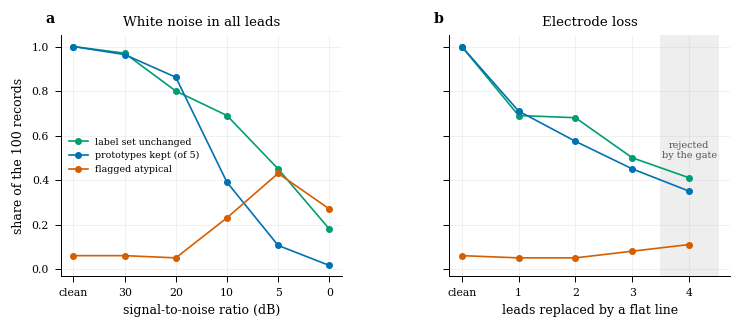

In [18]:
ROB_ID = [int(r['sample_id'][3:]) for r in CLEAN[:CFG['rob_n']]]
XR = np.stack([get_sig(ROW_OF[e]) for e in ROB_ID]); NR = len(XR)
def run_pipe(X, bs=50):
    out = []
    for i in range(0, len(X), bs): out += PIPE.predict(X[i:i + bs], explain=True)
    return out
def summarise(base, cur):
    jac, same, ovl, atyp_, dp = [], [], [], [], []
    for b, c in zip(base, cur):
        sb, sc = set(b['labels']), set(c['labels'])
        jac.append(1.0 if not (sb | sc) else len(sb & sc) / len(sb | sc)); same.append(float(sb == sc))
        ovl.append(len({p['ecg_id'] for p in b['prototypes']} & {p['ecg_id'] for p in c['prototypes']}) / CFG['k_proto'])
        atyp_.append(float(c['prototypes'][0]['similarity'] < SIM_FLAG))
        dp.append(np.mean(np.abs(np.array([c['probabilities'][l] for l in LABELS]) - np.array([b['probabilities'][l] for l in LABELS]))))
    return dict(jaccard=float(np.mean(jac)), unchanged=float(np.mean(same)), prototype_overlap=float(np.mean(ovl)), atypical_rate=float(np.mean(atyp_)), mean_abs_dp=float(np.mean(dp)))
BASE = run_pipe(XR)
ROB = [dict(condition='clean', kind='clean', level=np.inf, **summarise(BASE, BASE))]
rs = np.random.RandomState(7)
for snr in CFG['snr_db']:
    Xn = XR.copy(); pw = (XR - XR.mean(2, keepdims=True)).var(2, keepdims=True)
    Xn = (XR + rs.randn(*XR.shape).astype(np.float32) * np.sqrt(pw * 10 ** (-snr / 10))).astype(np.float32)
    ROB.append(dict(condition=f'noise {snr} dB', kind='noise', level=snr, **summarise(BASE, run_pipe(Xn))))
for k in CFG['drop_leads']:
    Xd = XR.copy()
    for i in range(NR):
        for j in rs.choice(12, k, replace=False): Xd[i, j] = Xd[i, j].mean()
    ROB.append(dict(condition=f'{k} flat leads', kind='drop', level=k, **summarise(BASE, run_pipe(Xd))))
ROBD = pd.DataFrame(ROB); ROBD.to_csv(os.path.join(TAB_DIR, 'robustness.csv'), index=False)
print(ROBD.drop(columns=['kind', 'level']).round(3).to_string(index=False))
check('the clean condition reproduces itself exactly', ROBD.loc[0, 'unchanged'] == 1.0 and ROBD.loc[0, 'prototype_overlap'] == 1.0)
nz = ROBD[ROBD.kind == 'noise']
check('heavier noise changes the output more (probability drift grows from 30 dB to 0 dB)', float(nz.mean_abs_dp.iloc[-1]) > float(nz.mean_abs_dp.iloc[0]), f'{nz.mean_abs_dp.iloc[0]:.4f} -> {nz.mean_abs_dp.iloc[-1]:.4f}', level='warn')

fig, axs = plt.subplots(1, 2, figsize=(W2, 2.6), gridspec_kw=dict(wspace=0.38), sharey=True)
for ax, kind, xl, tl in ((axs[0], 'noise', 'signal-to-noise ratio (dB)', 'White noise in all leads'), (axs[1], 'drop', 'leads replaced by a flat line', 'Electrode loss')):
    d = ROBD[ROBD.kind == kind]; c0 = ROBD.iloc[0]
    xv = list(d.level.values); xp = np.arange(len(xv) + 1)
    for col, c_, nm in (('unchanged', C_OK, 'label set unchanged'), ('prototype_overlap', '#0072B2', 'prototypes kept (of 5)'), ('atypical_rate', C_BAD, 'flagged atypical')):
        ax.plot(xp, [c0[col]] + list(d[col].values), marker='o', ms=3.2, color=c_, label=nm)
    ax.set_xticks(xp); ax.set_xticklabels(['clean'] + [str(int(v)) for v in xv]); ax.set_xlabel(xl); ax.set_title(tl); ax.set_ylim(-0.03, 1.05)
    if kind == 'drop': ax.axvspan(3.5, len(xv) + 0.5, color='#EEEEEE', zorder=0); ax.text(4.0, 0.5, 'rejected\nby the gate', fontsize=5.8, color='#555555', ha='center')
axs[0].set_ylabel('share of the 100 records'); axs[0].legend(fontsize=5.6, loc='center left'); panel(axs[0], 'a'); panel(axs[1], 'b')
save_fig(fig, 'fig11_robustness')

## 11. Using the deployed code on its own
A user of the system does not need this notebook, only the files written to the working folder (`hidmamba_deploy.py`, `hidmamba_infer.py`, `deploy_calibration.json`) plus the artefacts of Stages 3, 8, 9 and 10. Two ways are tested here: the Python API, and the command line on a saved `.npy` record.

In [19]:
from hidmamba_deploy import load_service
svc2 = load_service(P['deploy'], P['dean'], P['frozen'], IDX_ROOT, os.path.join(WORK, 'deploy_calibration.json'), device=str(dev))
r_api = svc2.analyse(xA, 'api-test')
check('the public API (load_service + analyse) returns the same report as the service used in this notebook',
      r_api['labels'] == rA['labels'] and np.allclose([r_api['probabilities'][l] for l in LABELS], [rA['probabilities'][l] for l in LABELS], atol=1e-6) and [p['ecg_id'] for p in r_api['prototypes']] == [p['ecg_id'] for p in rA['prototypes']])
del svc2
np.save(os.path.join(WORK, 'demo_ecg.npy'), np.stack([xA, get_sig(ROW_OF[int(exB['sample_id'][3:])])]))
cmd = [sys.executable, os.path.join(WORK, 'hidmamba_deploy.py'), '--deploy', P['deploy'], '--dean', P['dean'], '--frozen', P['frozen'], '--index-root', IDX_ROOT,
       '--calib', os.path.join(WORK, 'deploy_calibration.json'), '--device', 'cpu', os.path.join(WORK, 'demo_ecg.npy')]
t0 = time.time(); rc = subprocess.run(cmd, capture_output=True, text=True, cwd=WORK)
print(f'command line run: return code {rc.returncode} in {time.time() - t0:.0f} s'); print(rc.stdout[:1200] + rc.stderr[-600:])
lab_line = lambda s: next((l.strip() for l in s.split('\n') if l.strip().startswith('diagnostic labels')), None)
check('the command line prints a report for each of the two records', rc.returncode == 0 and rc.stdout.count('nearest prototype ECGs') == 2)
check('command line (CPU, fp32 DEAN) and notebook agree on the diagnostic labels of record 1', lab_line(rc.stdout) == lab_line(render_report(rA)), str(lab_line(rc.stdout)), level='warn')

[ok] the public API (load_service + analyse) returns the same report as the service used in this notebook
command line run: return code 0 in 9 s
ECG demo_ecg.npy#0   input: ACCEPT
  diagnostic labels: MI, IMI
    MI         p=0.93 (threshold 0.35)  3/5 nearest prototypes carry it; precision at this support on validation: 63%
    IMI        p=0.93 (threshold 0.29)  3/5 nearest prototypes carry it; precision at this support on validation: 63%
  nearest prototype ECGs:
    1. ecg 11018  similarity 0.671  labels: MI, IMI
    2. ecg 2591  similarity 0.639  labels: none
    3. ecg 21086  similarity 0.619  labels: none
    4. ecg 16273  similarity 0.619  labels: MI, IMI
    5. ecg 19646  similarity 0.614  labels: MI, IMI
  latency 410 ms
ECG demo_ecg.npy#1   input: ACCEPT
  diagnostic labels: NORM
    NORM       p=0.97 (threshold 0.36)  5/5 nearest prototypes carry it; precision at this support on validation: 88%
  nearest prototype ECGs:
    1. ecg 3831  similarity 0.588  labels: NORM
    2.

True

## 12. Export, manifest and summary

In [20]:
FILES = ['hidmamba_deploy.py', 'hidmamba_infer.py', 'deploy_calibration.json']
MAN = dict(stage=11, created=time.strftime('%Y-%m-%d %H:%M:%S'), versions=VERSIONS, frozen_config_sha256=sha256(P['frozen']), stage10_artefact_hashes=HASHES,
           deployable_code={f: sha256(os.path.join(WORK, f)) for f in FILES}, libraries={f: sha256(os.path.join(WORK, f)) for f in ('cr_lib.py', 'dean_lib.py', 'proto_lib.py')},
           needs=['chief_resident_deploy.pt', 'dean_finetuned.pt', 'frozen_config.json', 'prototype_meta.npz', 'prototype_config.json', 'index_trainval.faiss', 'faiss-cpu', 'torch'],
           usage="from hidmamba_deploy import load_service; svc = load_service(deploy, dean, frozen, index_root, 'deploy_calibration.json'); report = svc.analyse(ecg_12x1000, 'id'); for r in svc.stream(items): ...",
           input_contract='12 leads x 1000 samples, 100 Hz, millivolts, PTB-XL lead order I, II, III, aVR, aVL, aVF, V1-V6')
json.dump(MAN, open(os.path.join(WORK, 'deployment_bundle_manifest.json'), 'w'), indent=1)
n_fail = sum(c['status'] == 'FAIL' for c in CHECKS); n_warn = sum(c['status'] == 'WARN' for c in CHECKS)
M11 = dict(versions=VERSIONS, device=str(dev), n_stream=len(REPORTS), stream_seconds=STREAM_S, parameters=SVC_PARAMS, calibration={k: CALIB[k] for k in ('amp_lo', 'amp_hi', 'sim_flag')},
           support_table=CALIB['support_table'], consistency_with_stage10=CONS, latency_ms=LAT, monitoring=MON, robustness=ROBD.replace([np.inf], -1).to_dict('records'),
           examples={tag: dict(sample_id=r['sample_id'], why=why, labels=r['labels']) for tag, why, r in EXAMPLES},
           checks=CHECKS, n_pass=sum(c['status'] == 'PASS' for c in CHECKS), n_warn=n_warn, n_fail=n_fail, runtime_minutes=(time.time() - NB_T0) / 60)
json.dump(M11, open(os.path.join(WORK, 'stage11_metrics.json'), 'w'), indent=1, default=float)
pd.DataFrame(CHECKS).to_csv(os.path.join(TAB_DIR, 'checks.csv'), index=False)

print('=' * 100); print('STAGE 11 SUMMARY'); print('=' * 100)
print(f'Service: Chief Resident {N_PARAMS_CR / 1e6:.2f} M parameters + frozen DEAN embedding + exact FAISS search over {len(PIPE.ret.ecg_id):,} prototypes, on {dev}')
print(f'Stream: {len(REPORTS)} items one at a time ({dict(cnt_clean)} clean, {dict(cnt_bad)} stress); every stress item handled as expected')
print(f'Agreement with Stage 10 on {CONS["n"]} fold-10 records: max |dp| = {CONS["max_abs_dp"]:.1e}, label sets identical {CONS["label_sets_identical"]:.3f}, top-1 prototype identical {CONS["top1_neighbour_identical"]:.3f}, prototype overlap {CONS["mean_neighbour_overlap"]:.3f}')
print(f'Latency per record (median / p95): diagnosis {LAT["core_ms"]["median"]:.1f} / {LAT["core_ms"]["p95"]:.1f} ms, with explanation {LAT["latency_ms"]["median"]:.1f} / {LAT["latency_ms"]["p95"]:.1f} ms')
print('Precision of a predicted label by prototype support (fold 9): ' + ', '.join(f'{int(r.support)}/{CFG["k_proto"]}: {r.precision:.2f} (n={int(r.n)})' for r in SUP_TAB.itertuples() if r.n >= CFG['min_cell']))
print(f'Checks: {M11["n_pass"]} pass, {n_warn} warn, {n_fail} fail | runtime {M11["runtime_minutes"]:.1f} min')
print('=' * 100)
for c in CHECKS:
    if c['status'] != 'PASS': print(f'  [{c["status"]}] {c["check"]}: {c["detail"]}')
if CFG['strict'] and n_fail: raise AssertionError(f'{n_fail} check(s) failed')
print('Files in', WORK, ':', sorted(f for f in os.listdir(WORK) if not f.endswith('.pyc'))[:40])

STAGE 11 SUMMARY
Service: Chief Resident 0.89 M parameters + frozen DEAN embedding + exact FAISS search over 19,601 prototypes, on cuda
Stream: 210 items one at a time ({'accept': 200} clean, {'warn': 5, 'reject': 5} stress); every stress item handled as expected
Agreement with Stage 10 on 200 fold-10 records: max |dp| = 6.8e-07, label sets identical 1.000, top-1 prototype identical 1.000, prototype overlap 1.000
Latency per record (median / p95): diagnosis 8.3 / 9.2 ms, with explanation 89.9 / 98.6 ms
Precision of a predicted label by prototype support (fold 9): 0/5: 0.20 (n=657), 1/5: 0.35 (n=673), 2/5: 0.50 (n=681), 3/5: 0.63 (n=738), 4/5: 0.75 (n=879), 5/5: 0.88 (n=1413)
Checks: 51 pass, 0 warn, 0 fail | runtime 1.9 min
Files in /kaggle/working : ['__notebook__.ipynb', '__pycache__', 'cr_lib.py', 'dean_lib.py', 'demo_ecg.npy', 'deploy_calibration.json', 'deployment_bundle_manifest.json', 'example_reports.txt', 'figures', 'hidmamba_deploy.py', 'hidmamba_infer.py', 'proto_lib.py', 's